# Wave Glider Preflight / Dockside Diagnostic Notebook

Loads from the cache built by `parse_and_cache.ipynb`.
Iterates over each session defined in `mission_config.yml`.

**Workflow:**
1. Edit `config/mission_config.yml` — add sessions, phases, events
2. Run `parse_and_cache.ipynb` if raw data has changed
3. Run this notebook top to bottom
4. Fix everything red in the summary before departure


---
## 0. Setup

In [11]:
%load_ext autoreload
%autoreload 2

import os
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import matplotlib.font_manager as fm
import yaml

# --- Font setup ---
lexend_dir = os.path.expanduser('~/.fonts/Lexend')
if os.path.exists(lexend_dir):
    for f in os.listdir(lexend_dir):
        fm.fontManager.addfont(os.path.join(lexend_dir, f))
plt.rcParams['font.family'] = 'Lexend'
plt.rcParams['font.weight'] = 'light'
warnings.filterwarnings('ignore')




CONFIG_PATH = Path('config/mission_config.yml')
with open(CONFIG_PATH) as f:
    cfg = yaml.safe_load(f)

DATA_PATH  = Path(cfg['mission']['data_path'])
CACHE_PATH = DATA_PATH / 'cache'
MISSION    = cfg['mission']['name']
TZ         = cfg['mission'].get('timezone', 'UTC')

if not CACHE_PATH.exists():
    raise FileNotFoundError(f'Cache not found at {CACHE_PATH}\nRun parse_and_cache.ipynb first.')

# --- Sessions ---
# Each session has: name, start, end, phases (list), events (list)
# Falls back to a single session from test_period if no sessions defined
raw_sessions = cfg.get('sessions', [])
if not raw_sessions:
    tp = cfg.get('test_period', {})
    if 'start' in tp and 'end' in tp:
        raw_sessions = [{'name': MISSION,
                         'start': tp['start'], 'end': tp['end'],
                         'phases': cfg.get('phases', []),
                         'events': cfg.get('events', [])}]

SESSIONS = []
for s in raw_sessions:
    SESSIONS.append({
        'name':   s['name'],
        'start':  pd.Timestamp(s['start'], tz=TZ),
        'end':    pd.Timestamp(s['end'],   tz=TZ),
        'phases': s.get('phases', cfg.get('phases', [])),
        'type':   s.get('type', 'dockside'),
        'events': s.get('events', cfg.get('events', [])),
    })

print(f'Mission  : {MISSION}')
print(f'Cache    : {CACHE_PATH}')
print(f'Sessions : {len(SESSIONS)}')
for s in SESSIONS:
    print(f'  {s["name"]:30s}  {s["start"]} → {s["end"]}')

# --- Cache loader ---
def load_cache(name, as_dataframe=True):
    p = CACHE_PATH / f'{name}.nc'
    if not p.exists():
        print(f'  [cache miss] {name}.nc')
        return None
    ds = xr.open_dataset(p)
    tz_str = ds.attrs.get('timezone', 'UTC')
    if as_dataframe:
        df = ds.to_dataframe()
        if isinstance(df.index, pd.DatetimeIndex):
            df.index = df.index.tz_localize(tz_str)
        return df
    if 'time' in ds.coords:
        ds = ds.assign_coords(time=pd.DatetimeIndex(ds.time.values).tz_localize(tz_str))
    return ds

def clip(df, session):
    """Clip a DataFrame or Dataset to a session's time window."""
    if df is None:
        return None
    if isinstance(df, pd.DataFrame):
        if df.empty:
            return df
        return df.loc[session['start']:session['end']]
    # xarray Dataset
    t = df.coords['time']
    mask = (t >= session['start']) & (t <= session['end'])
    return df.sel(time=mask)

STATUS_PASS = '✅'
STATUS_WARN = '⚠️'
STATUS_FAIL = '❌'
STATUS_SKIP = '—'

# Global summary accumulator — collects results across all sessions
all_summary = []


The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
Mission  : WHIRLS Mission 3 - Dockside testing
Cache    : /Users/xedhjo/Documents/Data/WHIRLS/WHIRLS Mission 3 - Dockside testing/cache
Sessions : 3
  Dockside test 1 — 2026-05-21    2026-05-21 11:30:00+00:00 → 2026-05-21 15:15:00+00:00
  Dockside test 2 — 2026-05-26    2026-05-26 07:45:00+00:00 → 2026-05-26 14:30:00+00:00
  Dockside test 3 — IMU/Waves     2026-05-27 23:59:00+00:00 → 2026-06-01 12:00:00+00:00


---
## 1. Load cache

Load all sensors once — clips to each session later.

In [12]:
from src.waves import load_waves

print('Loading from cache...')
df_rbr  = load_cache('rbr')
df_wxt  = load_cache('wxt')
df_gill = load_cache('gill')
df_spn1 = load_cache('spn1')
df_cgr4 = load_cache('cgr4')
ds_adcp = load_cache('adcp_beam', as_dataframe=False)
if ds_adcp is None:
    ds_adcp = load_cache('adcp_enu', as_dataframe=False)
df_imu  = load_cache('imu')
df_gps  = load_cache('gps')
df_waves = load_cache('waves')

# Load spectra as xarray (not DataFrame)
ds_spectra = load_cache('spectra', as_dataframe=False)

# ADCP temperature as 1D DataFrame
df_adcp_temp = None
if ds_adcp is not None and 'temperature' in ds_adcp:
    df_adcp_temp = ds_adcp['temperature'].to_dataframe()[['temperature']]
    if df_adcp_temp.index.tz is None:
        df_adcp_temp.index = df_adcp_temp.index.tz_localize('UTC')

# Restore timezone on waves index if needed
if df_waves is not None and not df_waves.empty:
    if df_waves.index.tz is None:
        df_waves.index = df_waves.index.tz_localize('UTC')

print('Done.')

# Quick inventory
for name, obj in [
    ('RBR', df_rbr), ('WXT', df_wxt), ('Gill', df_gill),
    ('SPN1', df_spn1), ('CGR4', df_cgr4),
    ('ADCP', ds_adcp), ('IMU', df_imu), ('GPS', df_gps),
    ('Waves', df_waves), ('Spectra', ds_spectra),
]:
    if obj is None:
        print(f'  {name:<10} [not in cache]')
    elif hasattr(obj, 'empty') and obj.empty:
        print(f'  {name:<10} [empty]')
    elif hasattr(obj, 'time'):
        print(f'  {name:<10} {len(obj.time):>8,} records')
    else:
        print(f'  {name:<10} {len(obj):>8,} records')


Loading from cache...
Done.
  RBR          33,209 records
  WXT          33,191 records
  Gill        663,565 records
  SPN1          1,107 records
  CGR4          1,159 records
  ADCP          6,320 records
  IMU        7,061,272 records
  GPS        1,516,680 records
  Waves           212 records
  Spectra         212 records


---
## 2. Data coverage

Gantt view showing which sensors have data and when. Each bar = a contiguous block of data. Gaps are visible as breaks.

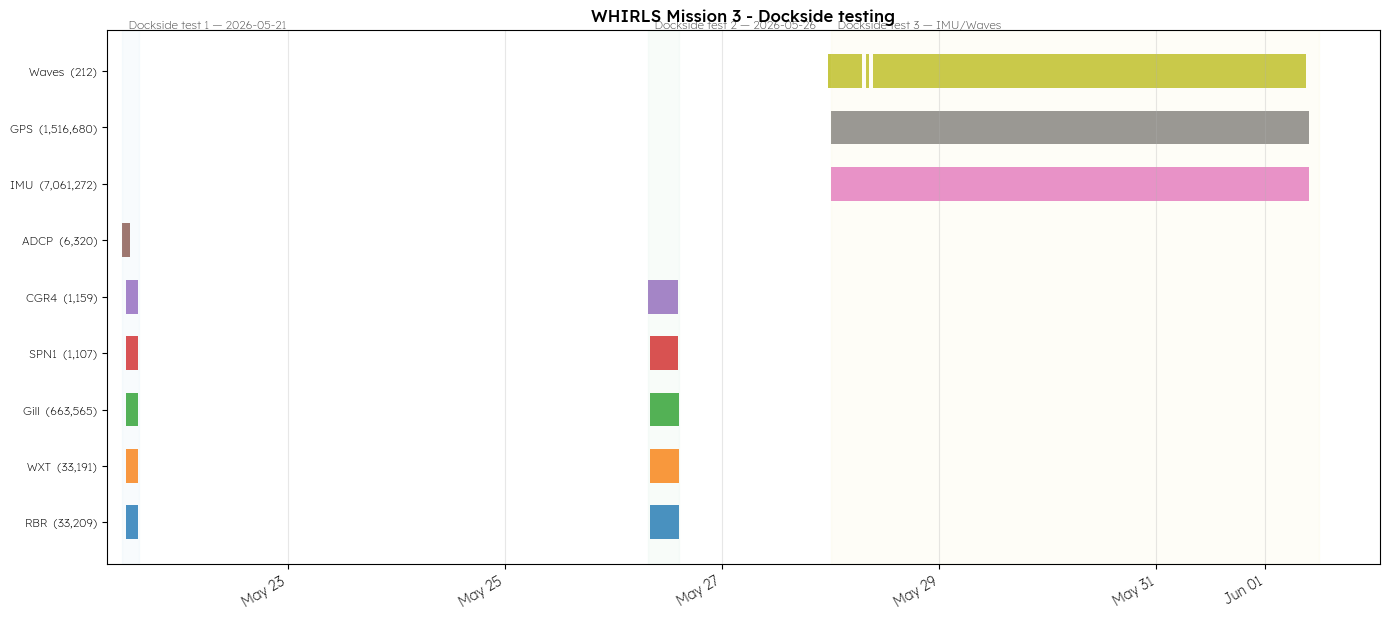

In [13]:
from src.diagnostics import plot_data_coverage_sessions

all_streams = {
    'RBR':    df_rbr,
    'WXT':    df_wxt,
    'Gill':   df_gill,
    'SPN1':   df_spn1,
    'CGR4':   df_cgr4,
    'ADCP':   df_adcp_temp,
    'IMU':    df_imu,
    'GPS':    df_gps,
    'Waves':  df_waves,
}

plot_data_coverage_sessions(all_streams, SESSIONS, title=MISSION)


---
## 3. Per-session diagnostics

Each session runs the full diagnostic suite independently.


  SESSION: Dockside test 1 — 2026-05-21
  2026-05-21 11:30:00+00:00 → 2026-05-21 15:15:00+00:00

[✅] RBR CTD — Sampling rate: median Δt = 1.0000s (expected 1.0s ± 0.1s)
[✅] RBR CTD — Variable ranges: all 7 variables present and in range


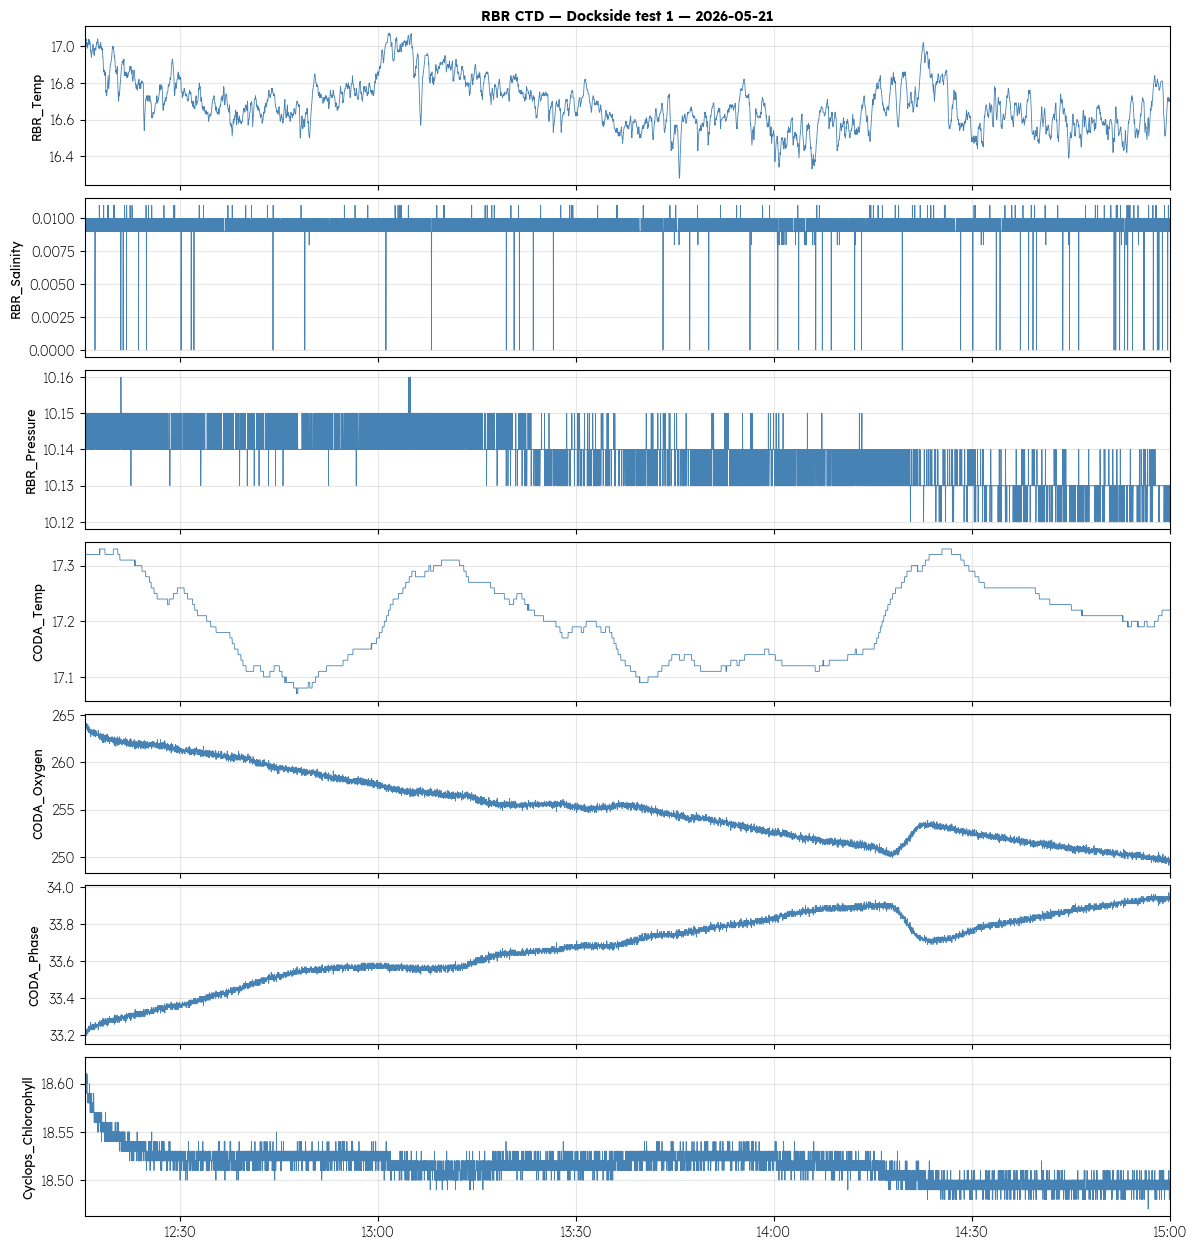

[✅] Vaisala WXT536 — Sampling rate: median Δt = 1.0000s (expected 1.0s ± 0.1s)
[✅] Vaisala WXT536 — Variable ranges: all 9 variables present and in range


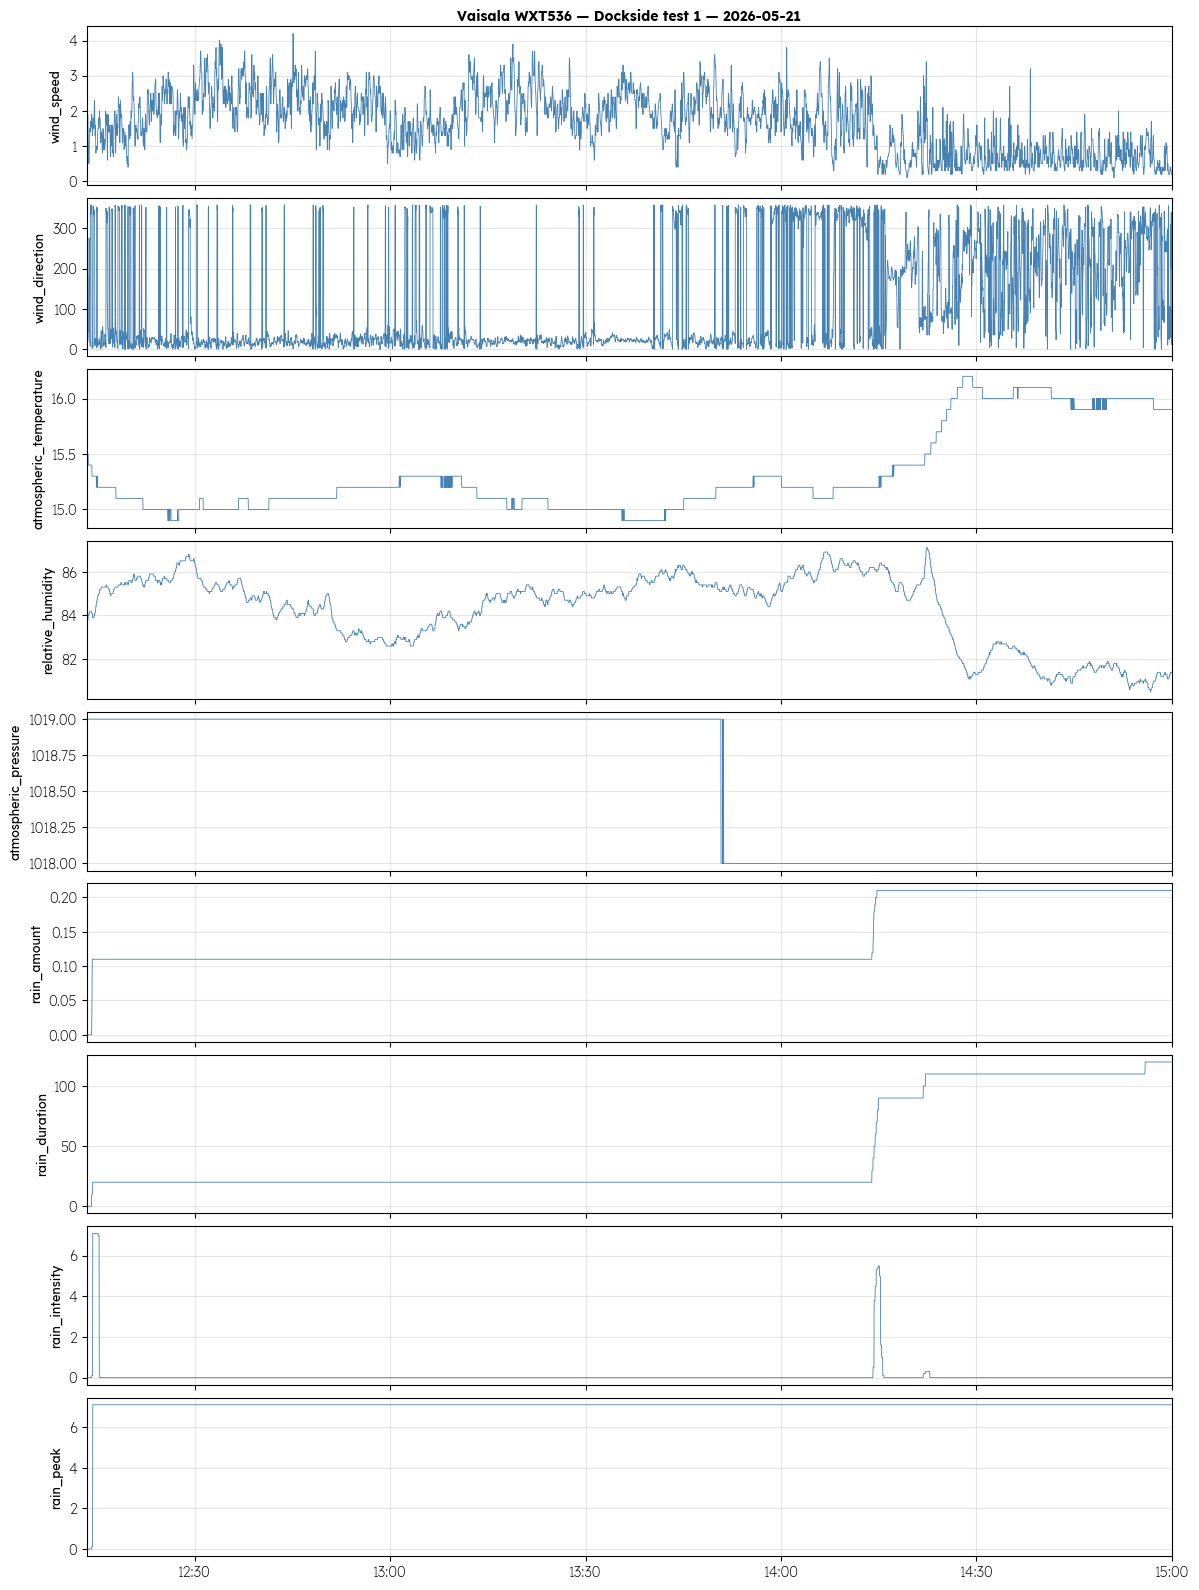

[✅] Gill Sonic Anemometer — Sampling rate: median Δt = 0.0500s (expected 0.05s ± 0.01s)
[✅] Gill Sonic Anemometer — Variable ranges: all 5 variables present and in range


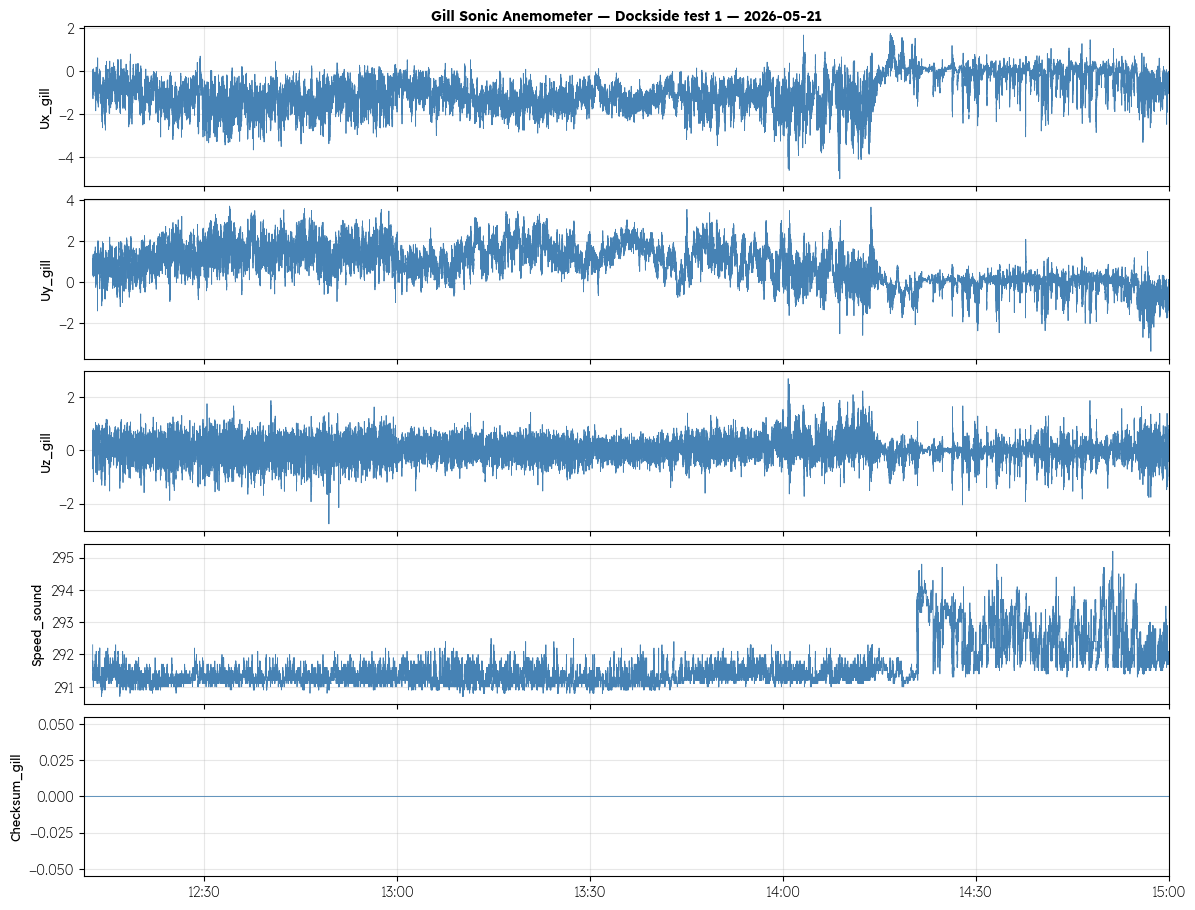

[✅] CGR4 Pyrgeometer (longwave) — Sampling rate: median Δt = 30.0000s (expected 30.0s ± 2.0s)
[⚠️] CGR4 Pyrgeometer (longwave) — Variable ranges: CGR4_Rad: all NaN


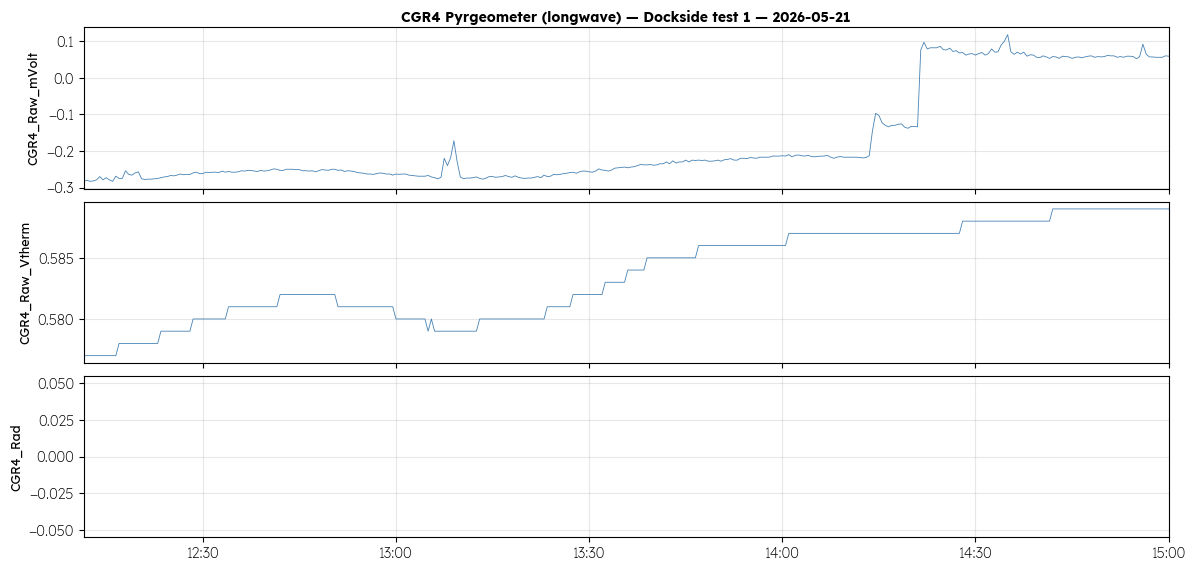

[✅] SPN1 Pyranometer (shortwave) — Sampling rate: median Δt = 30.0000s (expected 30.0s ± 2.0s)
[⚠️] SPN1 Pyranometer (shortwave) — Variable ranges: SPN1_Raw_Diffuse: 100.0% out of [-50, 1400]


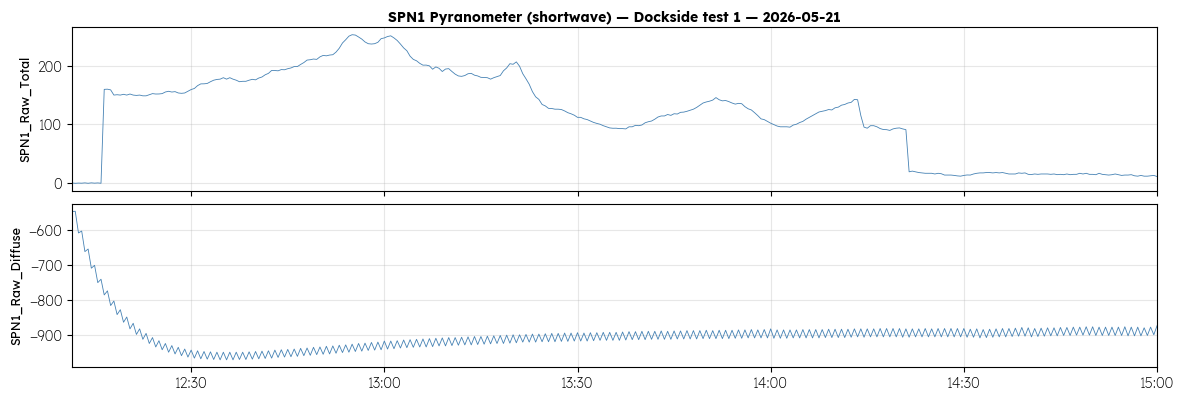

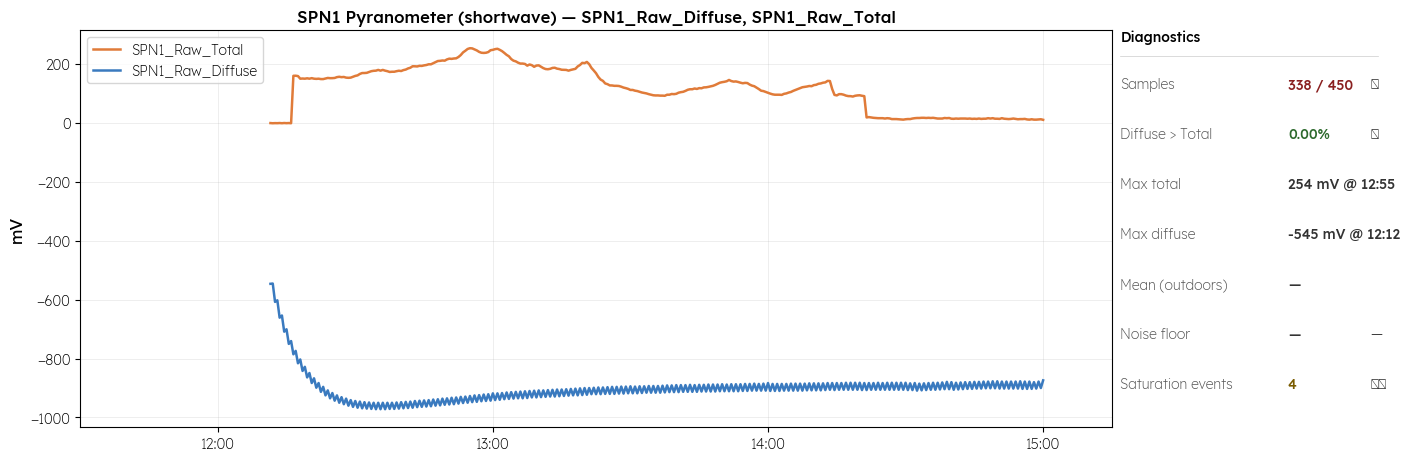

[✅] RDI WorkHorse 300 kHz ADCP — Sampling rate: median Δt = 1.000s (expected 1.0s)
[❌] RDI WorkHorse 300 kHz ADCP — Beam correlation: 2.0% above correlation threshold (64)
[⚠️] RDI WorkHorse 300 kHz ADCP — Velocity range (dockside): 99.1% outside [-3.0, 3.0] m/s


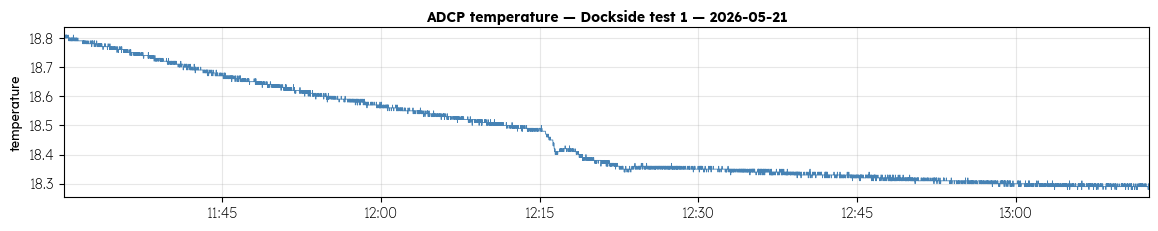

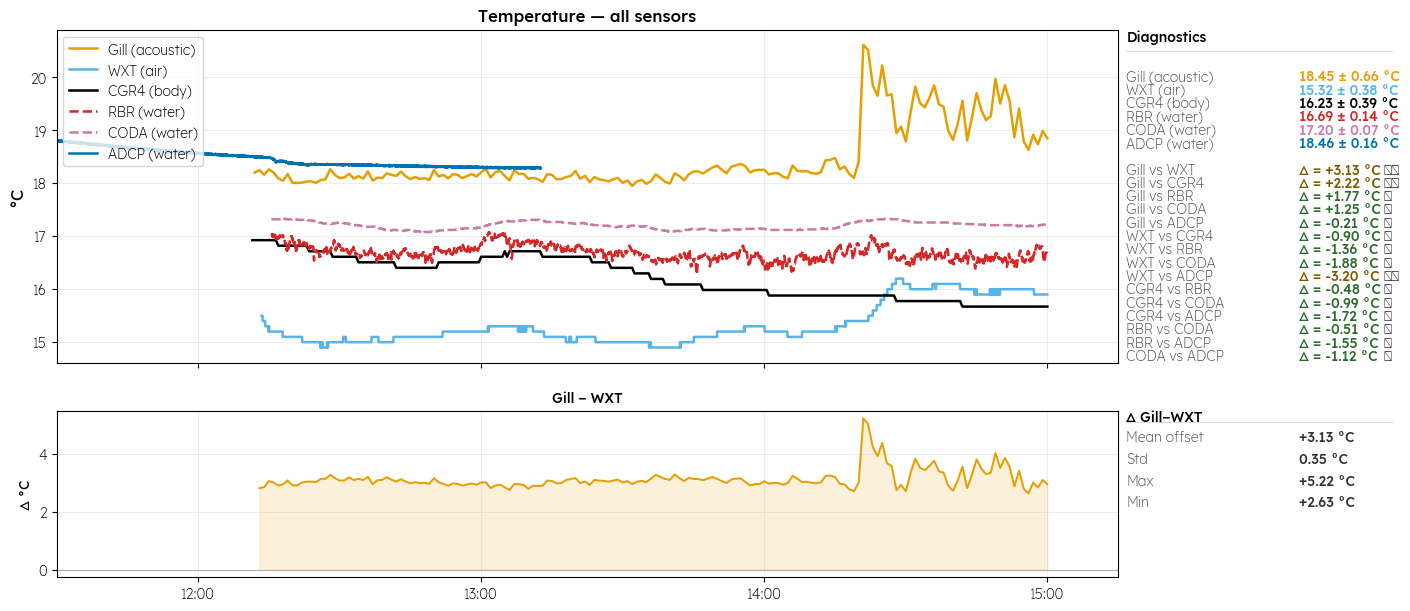


--- Summary: Dockside test 1 — 2026-05-21 ---

  PREFLIGHT SUMMARY  —  Dockside test 1 — 2026-05-21
  ✅ 9 passed   ⚠️  4 warnings   ❌ 1 failed



,sensor,check,status,detail
0,RBR CTD,Sampling rate,✅,median Δt = 1.0000s (expected 1.0s ± 0.1s)
1,RBR CTD,Variable ranges,✅,all 7 variables present and in range
2,Vaisala WXT536,Sampling rate,✅,median Δt = 1.0000s (expected 1.0s ± 0.1s)
3,Vaisala WXT536,Variable ranges,✅,all 9 variables present and in range
4,Gill Sonic Anemometer,Sampling rate,✅,median Δt = 0.0500s (expected 0.05s ± 0.01s)
5,Gill Sonic Anemometer,Variable ranges,✅,all 5 variables present and in range
6,CGR4 Pyrgeometer (longwave),Sampling rate,✅,median Δt = 30.0000s (expected 30.0s ± 2.0s)
7,CGR4 Pyrgeometer (longwave),Variable ranges,⚠️,CGR4_Rad: all NaN
8,SPN1 Pyranometer (shortwave),Sampling rate,✅,median Δt = 30.0000s (expected 30.0s ± 2.0s)
9,SPN1 Pyranometer (shortwave),Variable ranges,⚠️,"SPN1_Raw_Diffuse: 100.0% out of [-50, 1400]"



  SESSION: Dockside test 2 — 2026-05-26
  2026-05-26 07:45:00+00:00 → 2026-05-26 14:30:00+00:00

[✅] RBR CTD — Sampling rate: median Δt = 1.0000s (expected 1.0s ± 0.1s)
[✅] RBR CTD — Variable ranges: all 7 variables present and in range


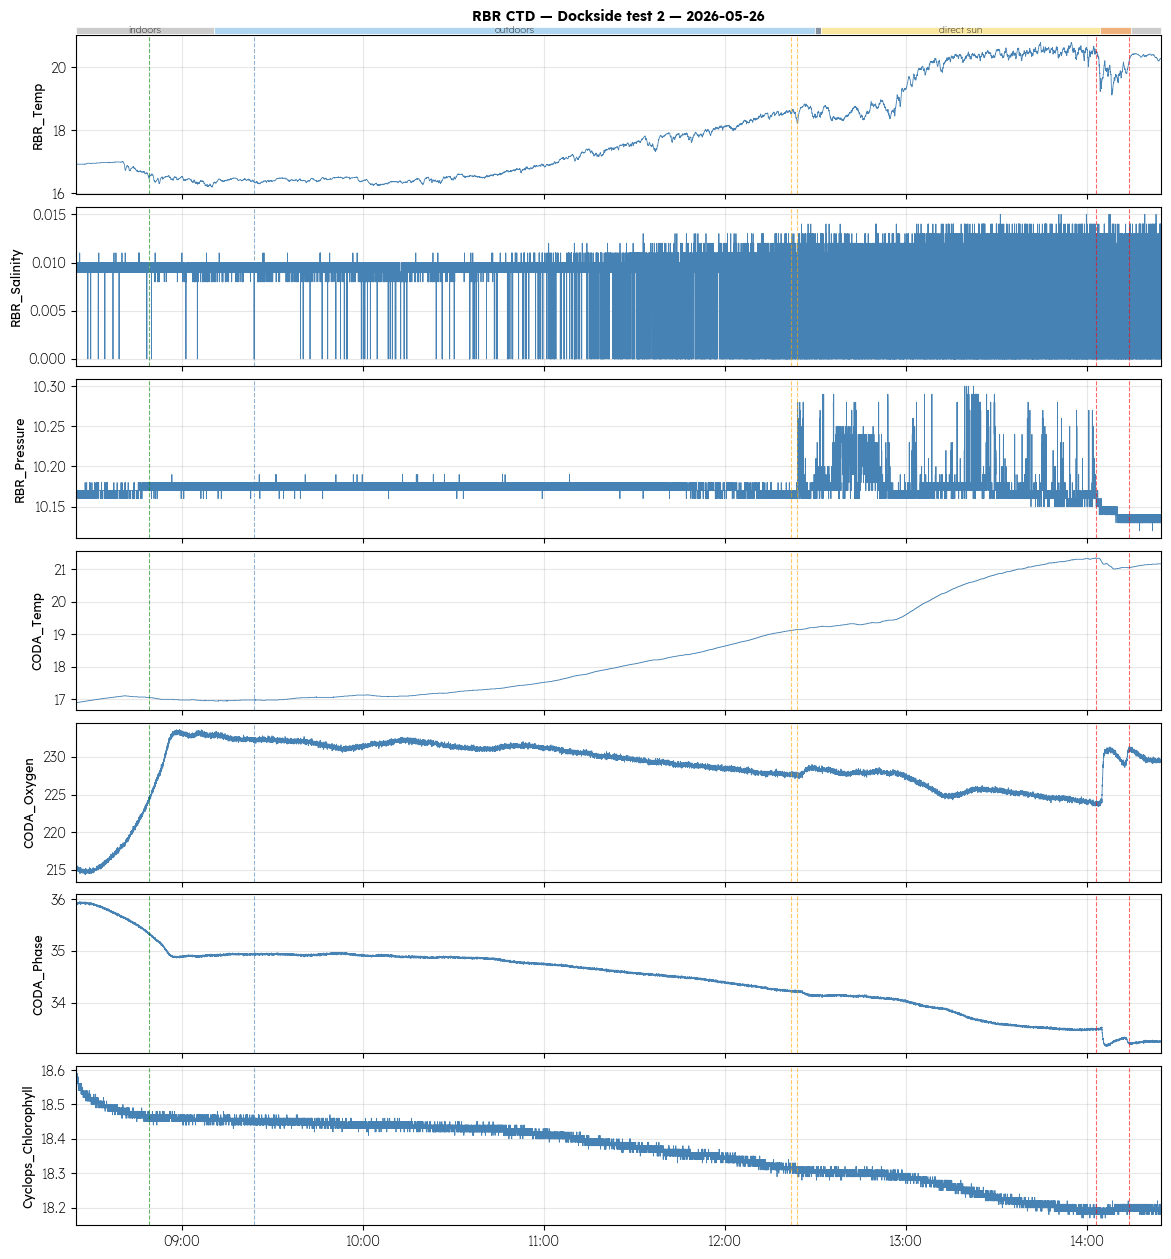

[✅] Vaisala WXT536 — Sampling rate: median Δt = 1.0000s (expected 1.0s ± 0.1s)
[✅] Vaisala WXT536 — Variable ranges: all 9 variables present and in range


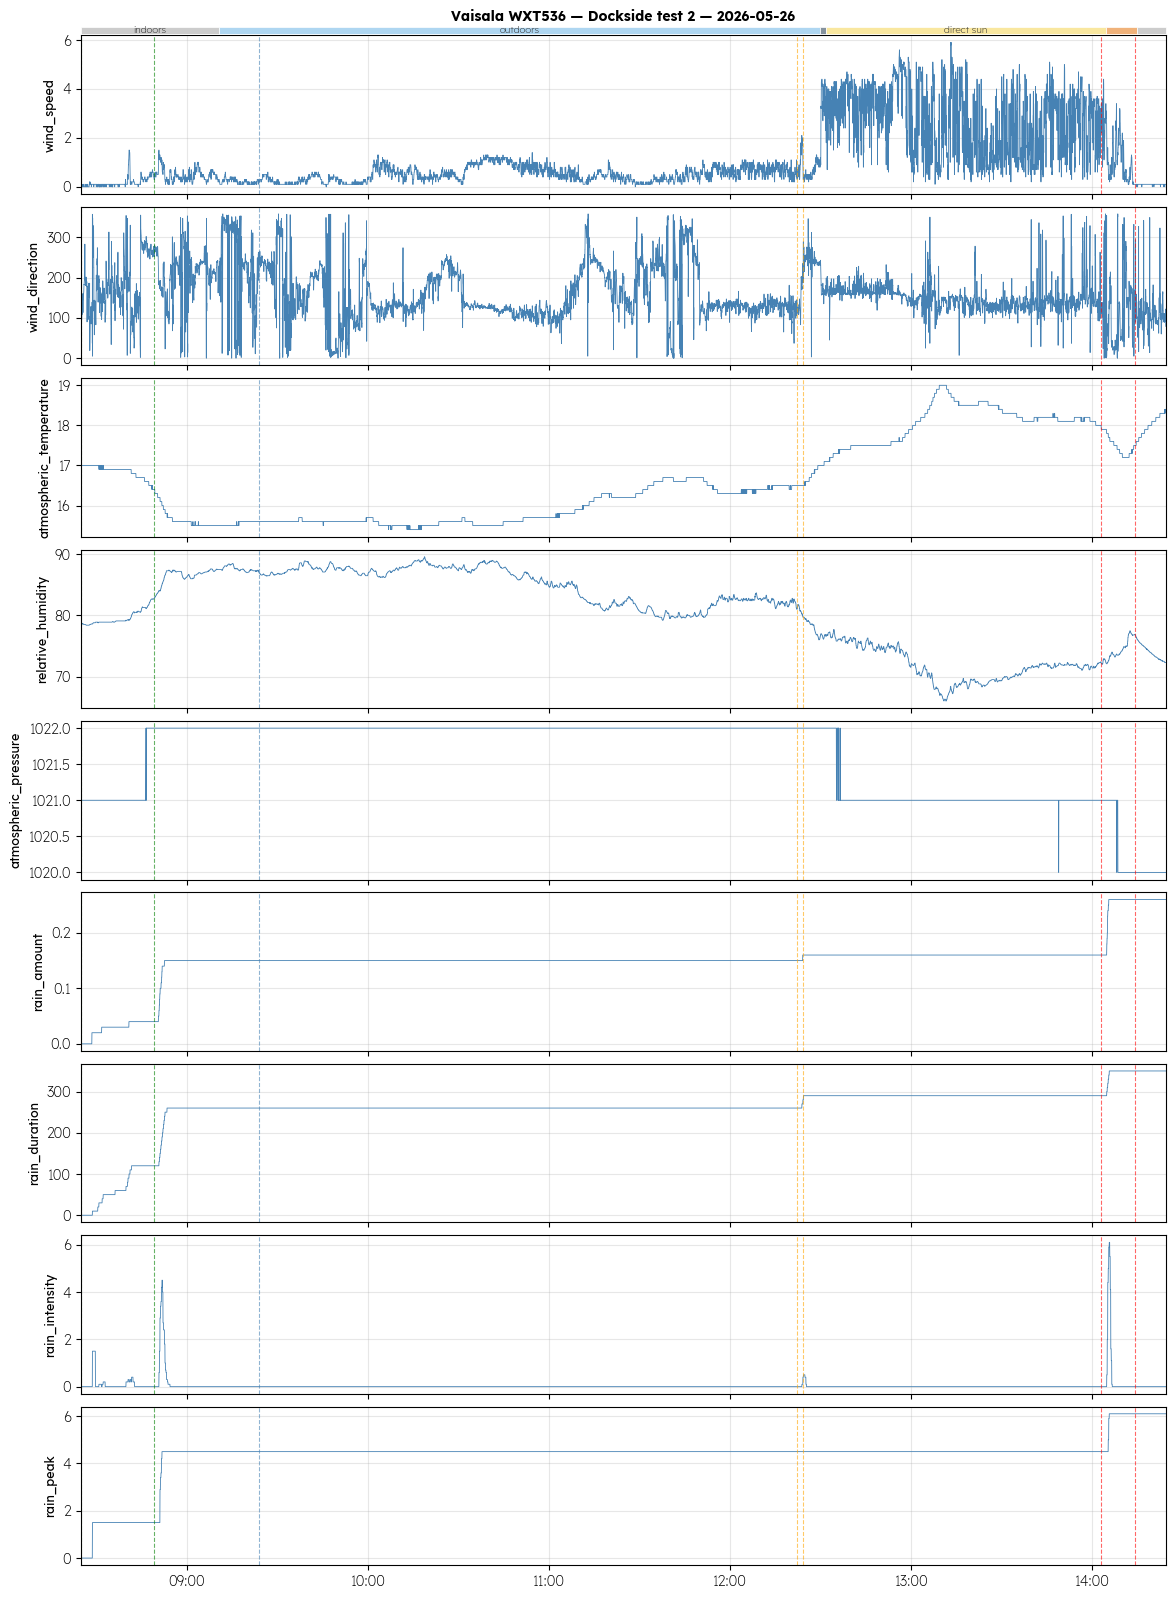

[✅] Gill Sonic Anemometer — Sampling rate: median Δt = 0.0500s (expected 0.05s ± 0.01s), 9 gap(s) > 0.2s
[✅] Gill Sonic Anemometer — Variable ranges: all 5 variables present and in range


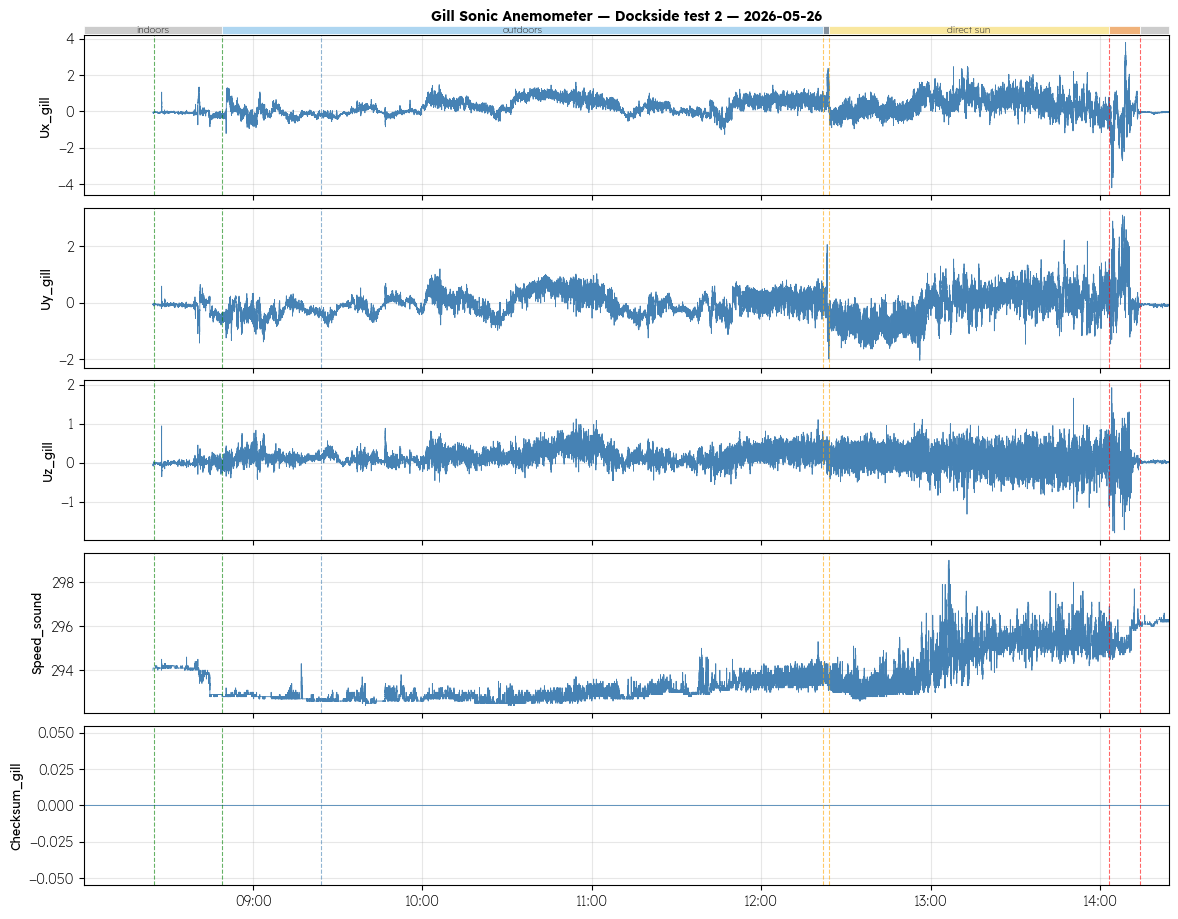

[✅] CGR4 Pyrgeometer (longwave) — Sampling rate: median Δt = 30.0000s (expected 30.0s ± 2.0s)
[✅] CGR4 Pyrgeometer (longwave) — Variable ranges: all 3 variables present and in range


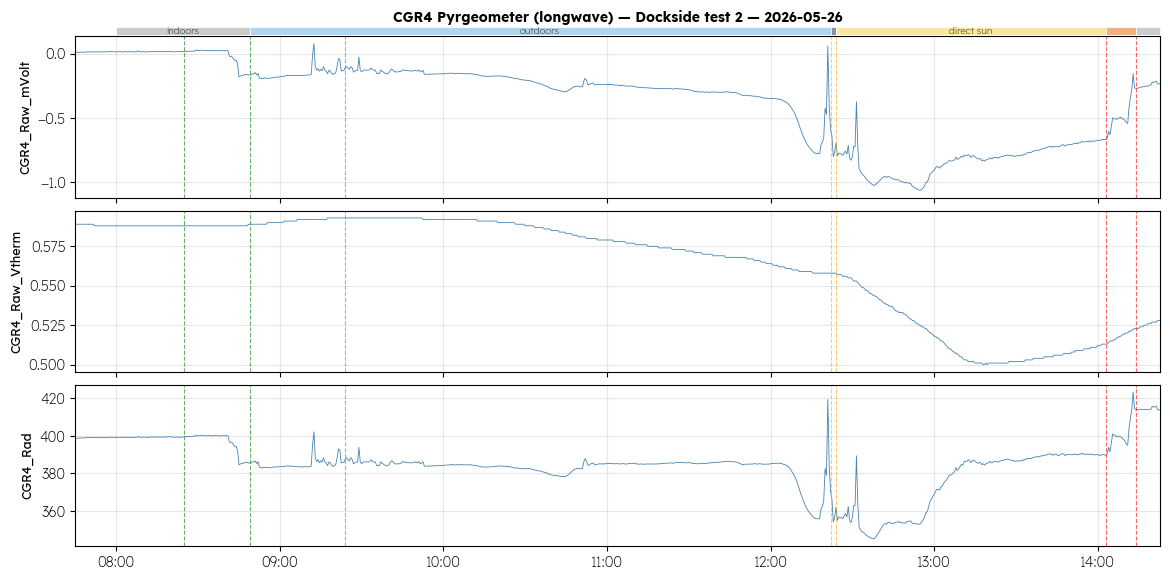

[✅] SPN1 Pyranometer (shortwave) — Sampling rate: median Δt = 30.0000s (expected 30.0s ± 2.0s)
[✅] SPN1 Pyranometer (shortwave) — Variable ranges: all 2 variables present and in range


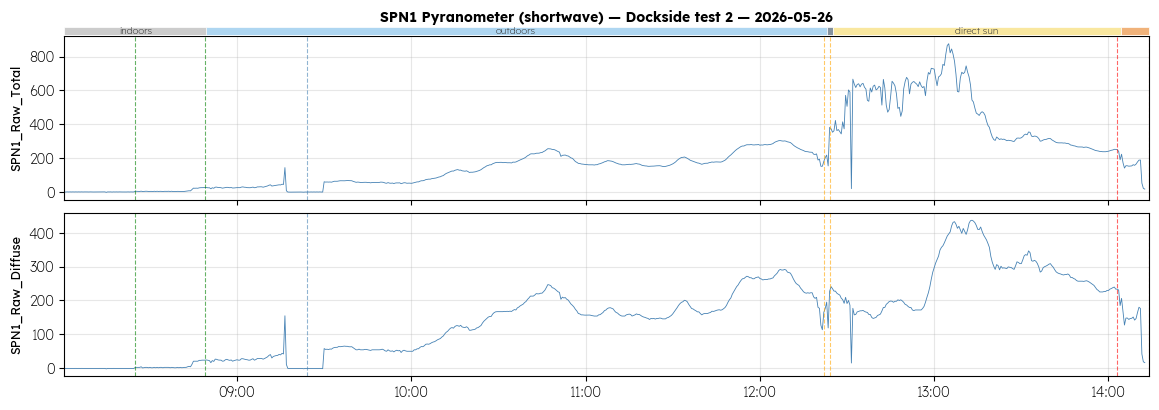

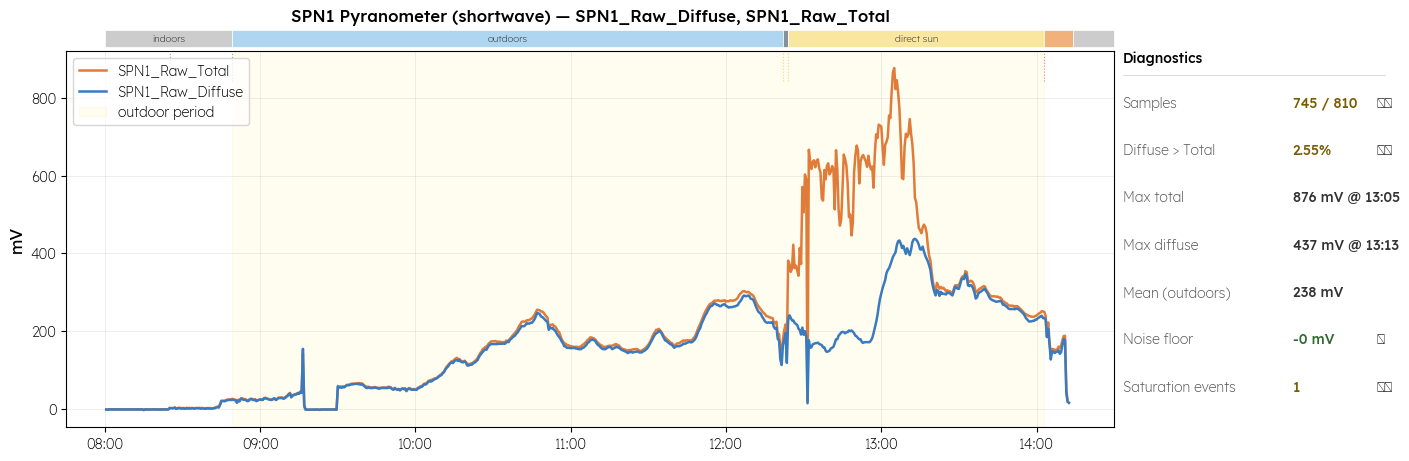

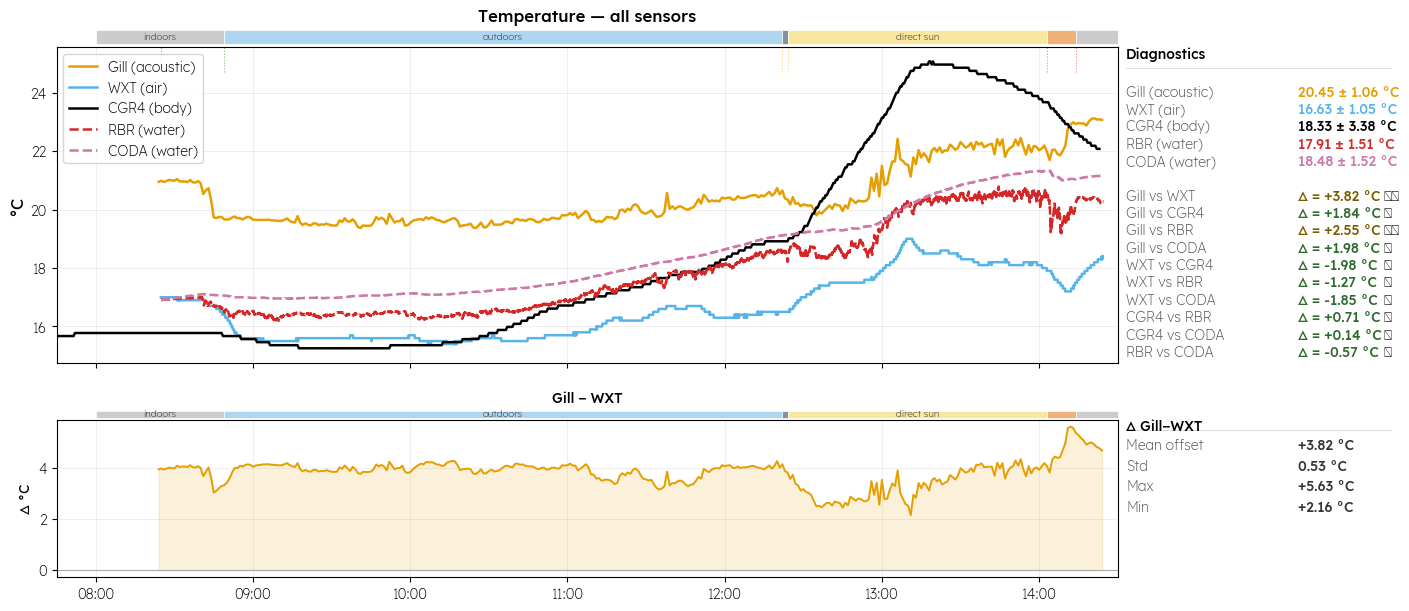


--- Summary: Dockside test 2 — 2026-05-26 ---

  PREFLIGHT SUMMARY  —  Dockside test 2 — 2026-05-26
  ✅ 10 passed   ⚠️  1 warnings   ❌ 0 failed



,sensor,check,status,detail
0,RBR CTD,Sampling rate,✅,median Δt = 1.0000s (expected 1.0s ± 0.1s)
1,RBR CTD,Variable ranges,✅,all 7 variables present and in range
2,Vaisala WXT536,Sampling rate,✅,median Δt = 1.0000s (expected 1.0s ± 0.1s)
3,Vaisala WXT536,Variable ranges,✅,all 9 variables present and in range
4,Gill Sonic Anemometer,Sampling rate,✅,"median Δt = 0.0500s (expected 0.05s ± 0.01s), 9 gap(s) > 0.2s"
5,Gill Sonic Anemometer,Variable ranges,✅,all 5 variables present and in range
6,CGR4 Pyrgeometer (longwave),Sampling rate,✅,median Δt = 30.0000s (expected 30.0s ± 2.0s)
7,CGR4 Pyrgeometer (longwave),Variable ranges,✅,all 3 variables present and in range
8,SPN1 Pyranometer (shortwave),Sampling rate,✅,median Δt = 30.0000s (expected 30.0s ± 2.0s)
9,SPN1 Pyranometer (shortwave),Variable ranges,✅,all 2 variables present and in range



  SESSION: Dockside test 3 — IMU/Waves
  2026-05-27 23:59:00+00:00 → 2026-06-01 12:00:00+00:00



Interval,Rate,Count,Share,,Class
249.0 ms,4.0 Hz,160,0.12%,,other
250.0 ms,4.0 Hz,"130,374",99.88%,,other
179341.0 ms,0.0 Hz,1,<0.01%,,gap
736154.0 ms,0.0 Hz,1,<0.01%,,gap


Interval,Rate,Count,Share,,Class
0.0 ms,—,262,<0.01%,,duplicate
49.0 ms,20.4 Hz,5,<0.01%,,nominal
49.0 ms,20.4 Hz,"1,234",0.02%,,nominal
49.0 ms,20.4 Hz,7,<0.01%,,nominal
50.0 ms,20.0 Hz,"219,923",3.17%,,nominal
50.0 ms,20.0 Hz,"6,489,319",93.63%,,nominal
50.0 ms,20.0 Hz,"219,922",3.17%,,nominal
99.0 ms,10.1 Hz,1,<0.01%,,other
99.0 ms,10.1 Hz,12,<0.01%,,other
149.0 ms,6.7 Hz,2,<0.01%,,other


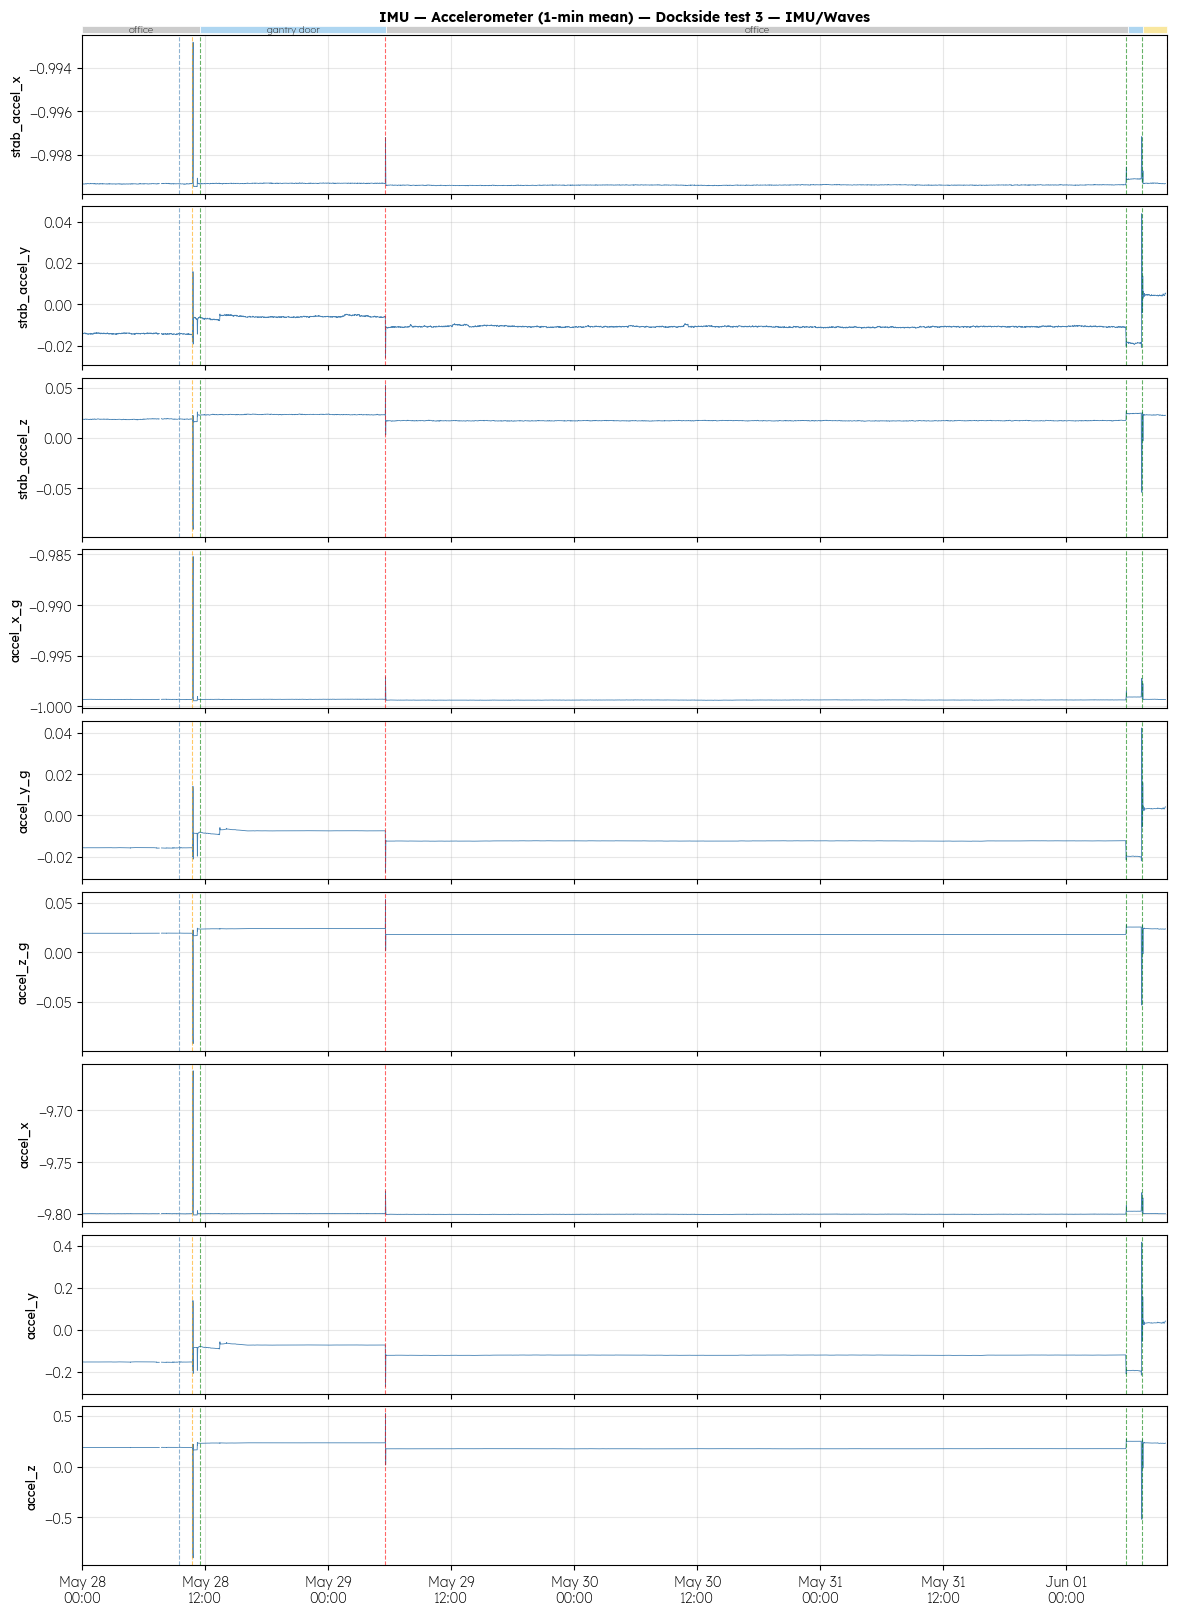

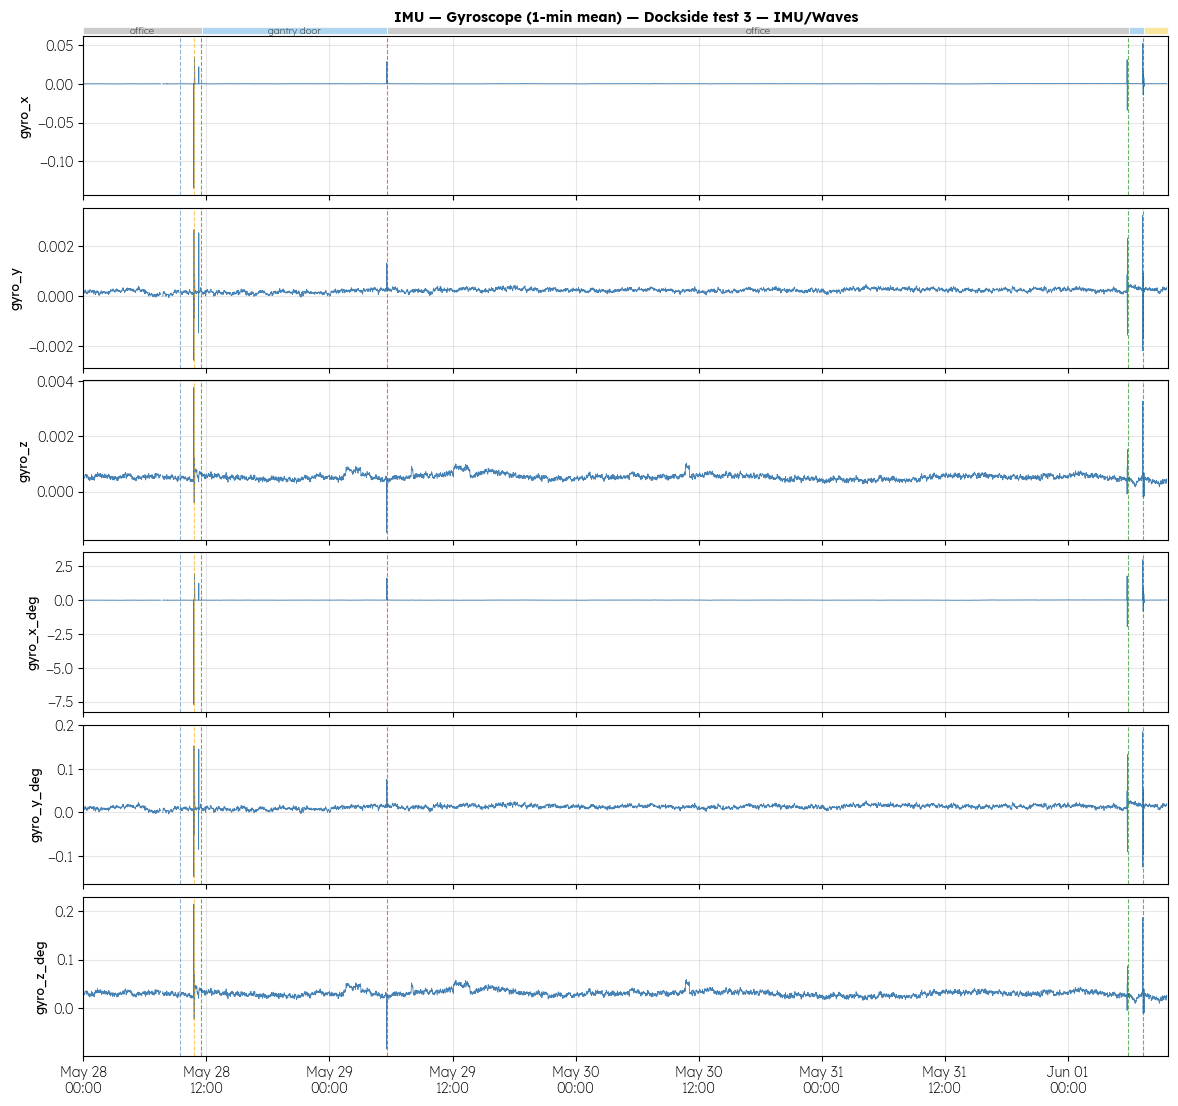

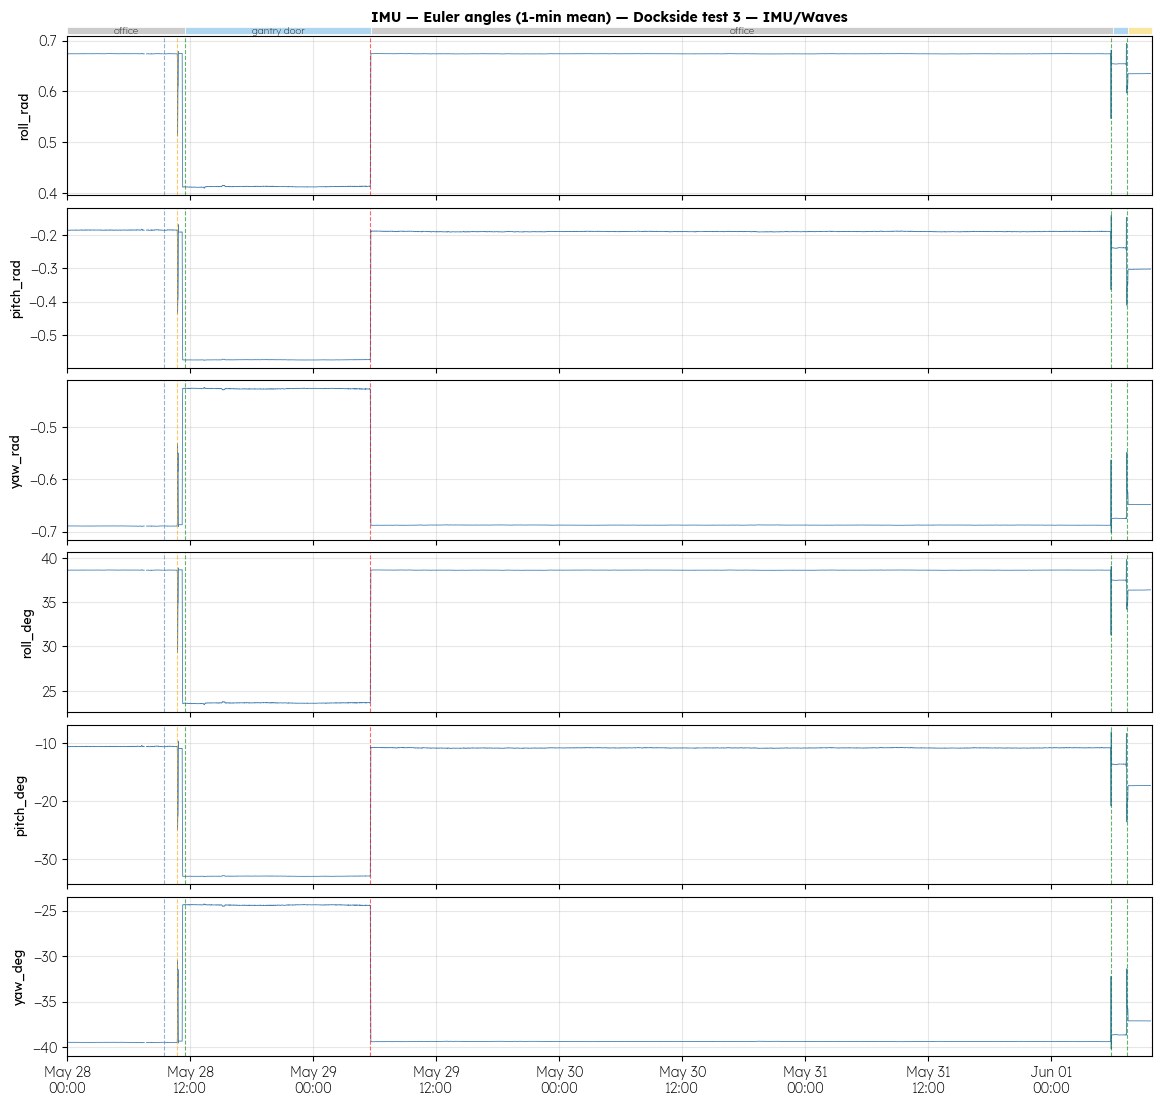

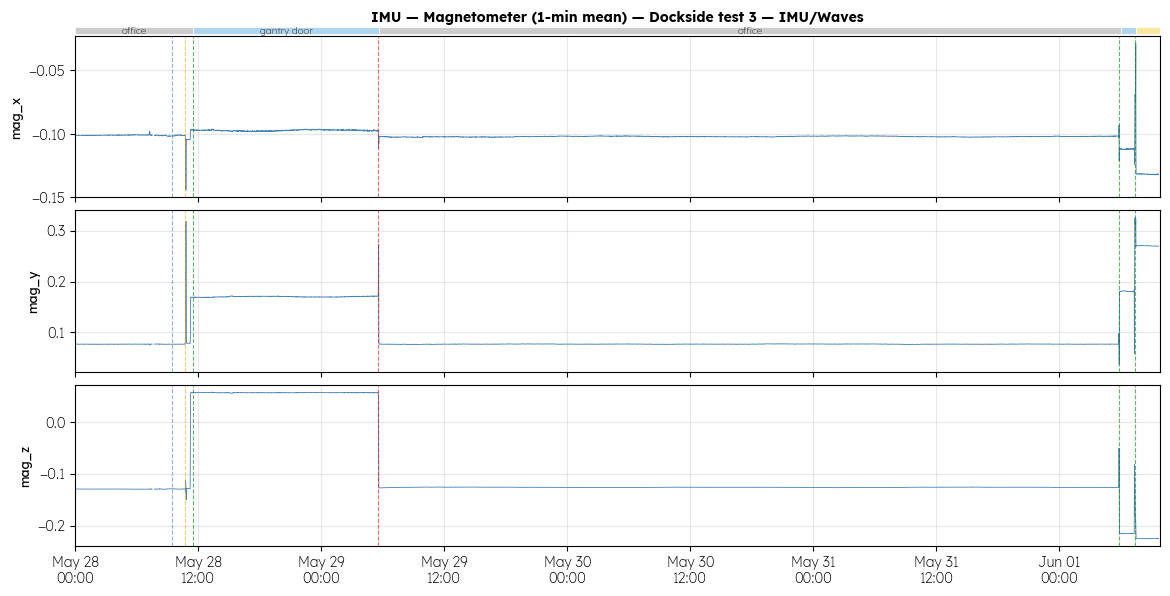

[✅] GPS — Sampling rate: median Δt = 0.2500s (expected 0.25s ± 0.1s), 3 gap(s) > 0.8s
[✅] GPS — Variable ranges: all 7 variables present and in range


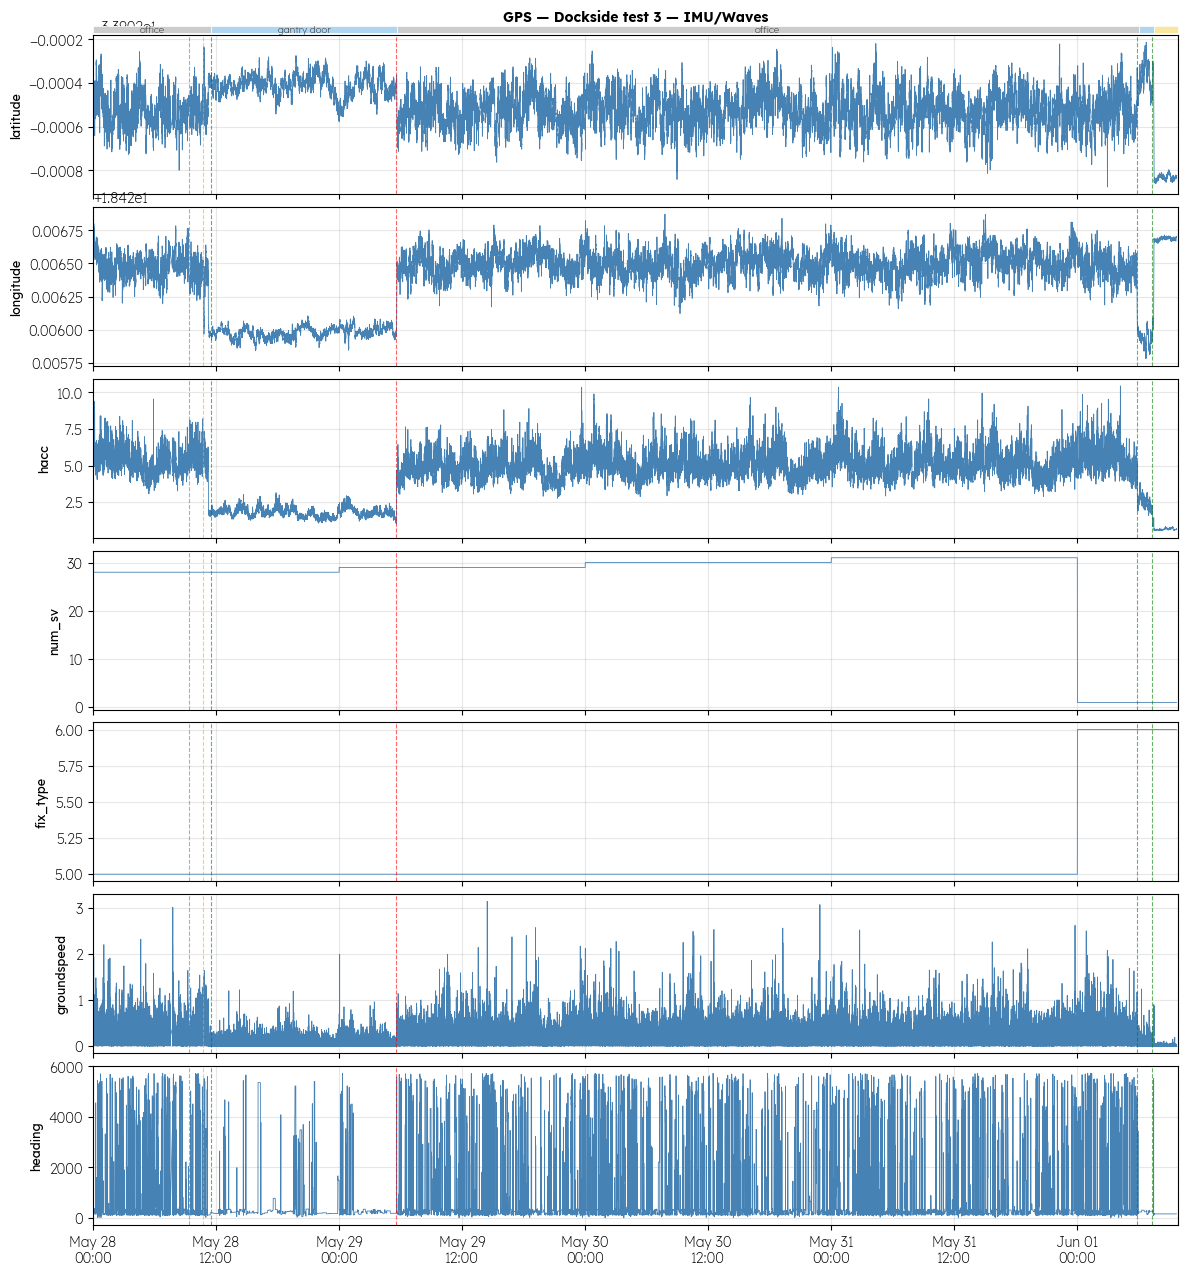

[✅] Wave stats — Sampling rate: median Δt = 1800.0000s (expected 1800s ± 120s)
[✅] Wave stats — Variable ranges: all 3 variables present and in range


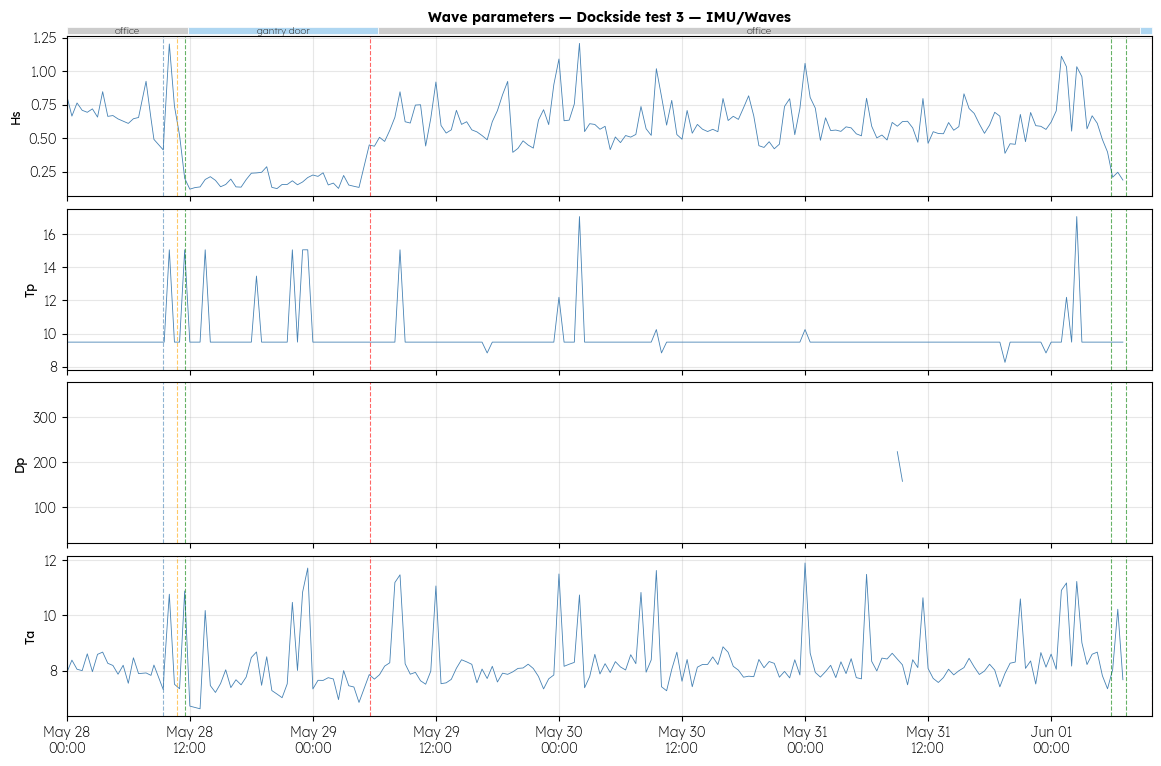

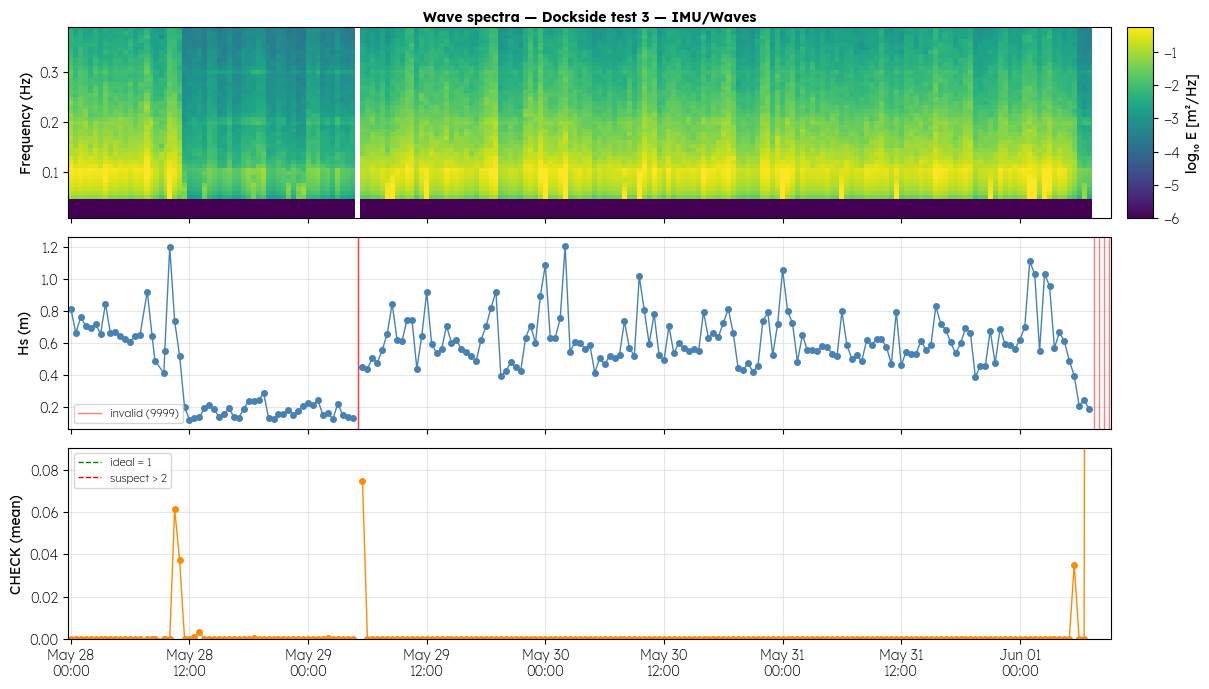

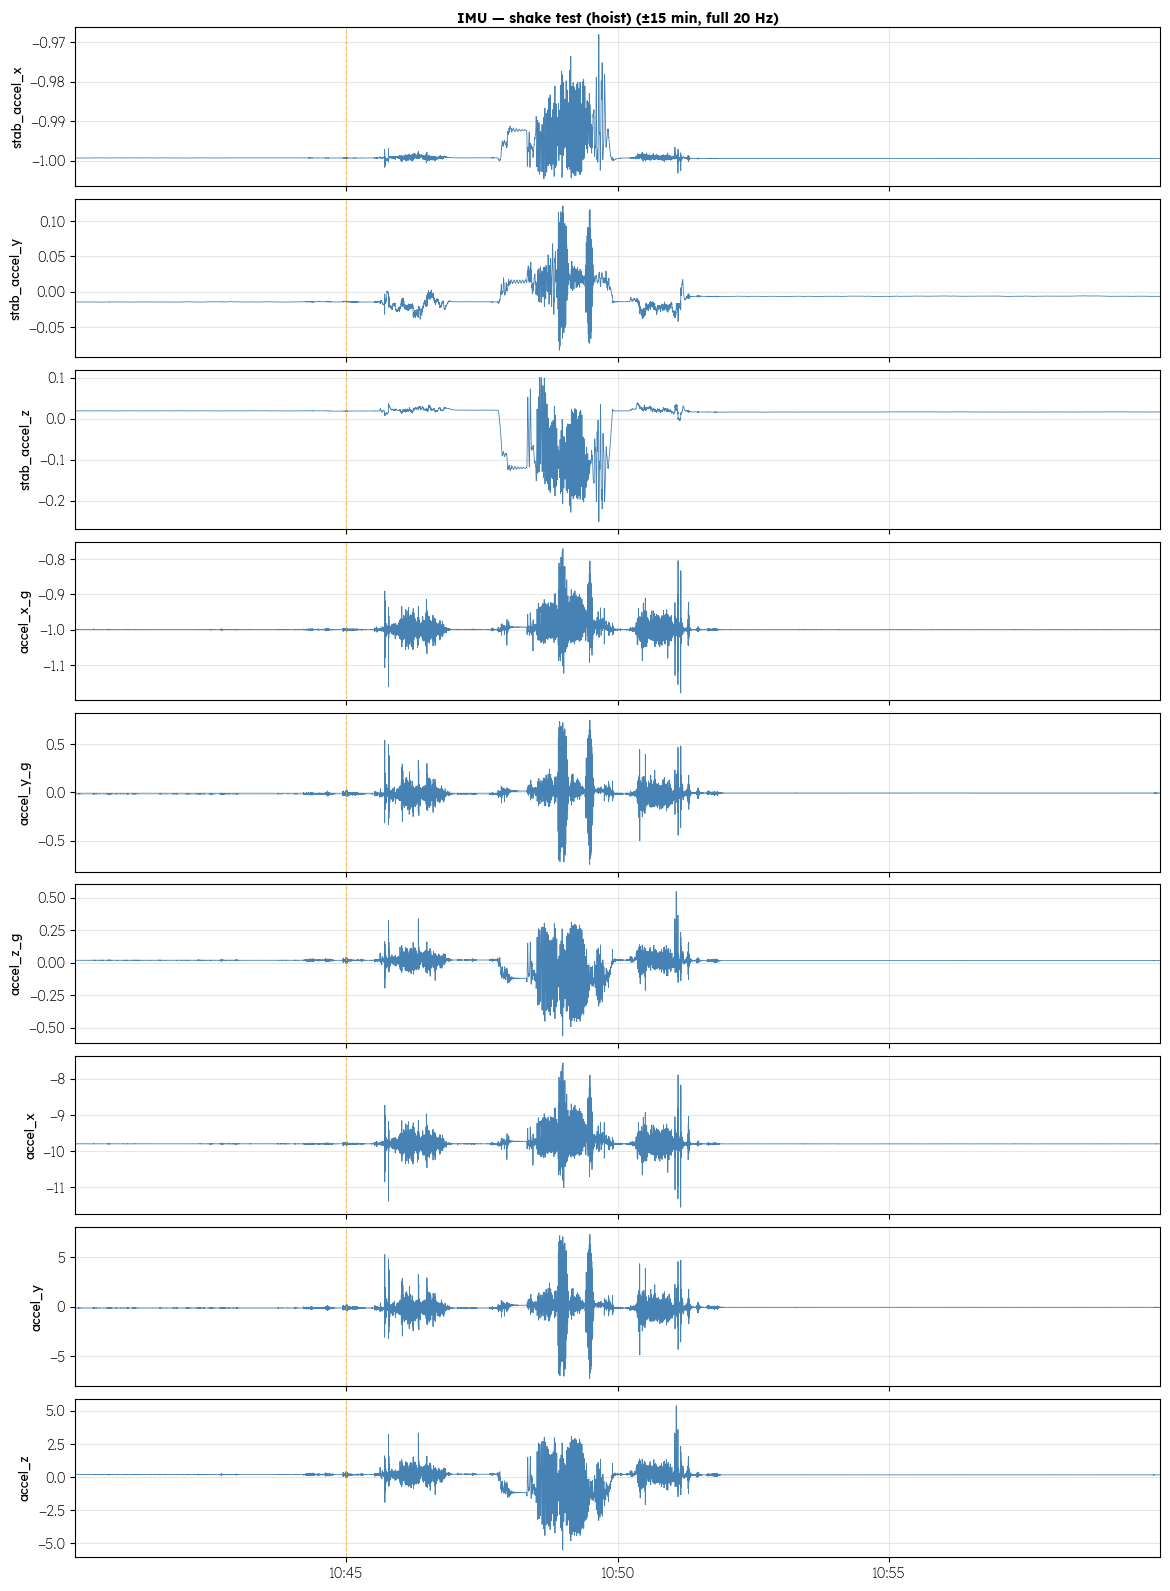


--- Summary: Dockside test 3 — IMU/Waves ---

  PREFLIGHT SUMMARY  —  Dockside test 3 — IMU/Waves
  ✅ 5 passed   ⚠️  0 warnings   ❌ 0 failed



,sensor,check,status,detail
0,IMU,IMU sampling rate,✅,expected 50 ms (20 Hz) — judged on post-change segment only
1,GPS,Sampling rate,✅,"median Δt = 0.2500s (expected 0.25s ± 0.1s), 3 gap(s) > 0.8s"
2,GPS,Variable ranges,✅,all 7 variables present and in range
3,Wave stats,Sampling rate,✅,median Δt = 1800.0000s (expected 1800s ± 120s)
4,Wave stats,Variable ranges,✅,all 3 variables present and in range


In [14]:
from src.diagnostics import (
    check_gps_quality,
    check_sampling_rate, check_variable_ranges,
    check_adcp, check_imu_sampling_rate,
    plot_timeseries, render_summary,
)
from src.plots import plot_spn1, plot_temperature_comparison

IMU_CONFIG_CHANGES = {
    'Dockside test 2 — 2026-05-26':  '09:24',
    'Dockside test 3 — IMU/Waves':    '2026-05-28 09:24',
}

for SESSION in SESSIONS:
    sname  = SESSION['name']
    tp     = (SESSION['start'], SESSION['end'])
    phases = SESSION['phases']
    events = SESSION['events']
    summary = []

    print(f'\n{"="*70}')
    print(f'  SESSION: {sname}')
    print(f'  {SESSION["start"]} → {SESSION["end"]}')
    print(f'{"="*70}\n')

    # Clip everything to this session window
    s = {k: clip(v, SESSION) for k, v in {
        'rbr':       df_rbr,
        'wxt':       df_wxt,
        'gill':      df_gill,
        'spn1':      df_spn1,
        'cgr4':      df_cgr4,
        'adcp':      ds_adcp,
        'imu':       df_imu,
        'gps':       df_gps,
        'waves':     df_waves,
        'adcp_temp': df_adcp_temp,
    }.items()}

    # Clip spectra separately (xarray, time coord may be tz-naive)
    s_spectra = None
    if ds_spectra is not None and len(ds_spectra.time) > 0:
        # Use isoformat strings — xarray handles tz-aware coords correctly
        t0_str = SESSION['start'].tz_convert('UTC').isoformat()
        t1_str = SESSION['end'].tz_convert('UTC').isoformat()
        s_spectra = ds_spectra.sel(time=slice(t0_str, t1_str))
        if len(s_spectra.time) == 0:
            s_spectra = None

    def has(key):
        v = s[key]
        if v is None: return False
        if hasattr(v, 'empty'): return not v.empty
        return len(v.time) > 0

    pt_kw = dict(phases=phases, events=events)  # passed to every plot_timeseries

    # ── Standard sensor plots ─────────────────────────────────────────────

    for key in ['rbr', 'wxt', 'gill', 'cgr4']:
        if not has(key): continue
        scfg = cfg['cr6'][key]
        if not scfg.get('enabled', True): continue
        summary.extend([
            check_sampling_rate(s[key], scfg, label=scfg['label']),
            check_variable_ranges(s[key], scfg, label=scfg['label']),
        ])
        plot_timeseries(s[key], scfg['variables'],
                        title=f"{scfg['label']} — {sname}", **pt_kw)

    # SPN1 standard timeseries + dedicated plot
    if has('spn1') and cfg['cr6']['spn1'].get('enabled', True):
        scfg = cfg['cr6']['spn1']
        summary.extend([
            check_sampling_rate(s['spn1'], scfg, label=scfg['label']),
            check_variable_ranges(s['spn1'], scfg, label=scfg['label']),
        ])
        plot_timeseries(s['spn1'], scfg['variables'],
                        title=f"{scfg['label']} — {sname}", **pt_kw)
        loc_events = [e for e in events if 'location' in e.get('tags', [])]
        outdoor = (loc_events[0]['time'], loc_events[-2]['time']) if len(loc_events) >= 2 else None
        plot_spn1(s['spn1'], scfg, test_period=tp, phases=phases,
                  events=events, outdoor_window=outdoor)

    # ADCP
    if has('adcp'):
        summary.extend(check_adcp(s['adcp'], cfg['adcp']))
        if 'temperature' in s['adcp']:
            df_adcp_t = s['adcp']['temperature'].to_dataframe()[['temperature']]
            if df_adcp_t.index.tz is None:
                df_adcp_t.index = df_adcp_t.index.tz_localize('UTC')
            plot_timeseries(df_adcp_t, ['temperature'],
                            title=f'ADCP temperature — {sname}', **pt_kw)

    # IMU
    if has('imu'):
        imu_change = IMU_CONFIG_CHANGES.get(sname)
        summary.append(check_imu_sampling_rate(
            s['imu'], cfg['gpswaves']['imu'],
            label='IMU', config_change=imu_change,
        ))
        imu_plot   = s['imu'].resample('1min').mean()
        accel_vars = [c for c in imu_plot.columns if 'accel' in c.lower()]
        gyro_vars  = [c for c in imu_plot.columns if 'gyro'  in c.lower()]
        euler_vars = [c for c in imu_plot.columns
                      if any(x in c.lower() for x in ['roll','pitch','yaw'])]
        mag_vars   = [c for c in imu_plot.columns if 'mag'   in c.lower()]
        for var_group, lbl in [
            (accel_vars, 'IMU — Accelerometer (1-min mean)'),
            (gyro_vars,  'IMU — Gyroscope (1-min mean)'),
            (euler_vars, 'IMU — Euler angles (1-min mean)'),
            (mag_vars,   'IMU — Magnetometer (1-min mean)'),
        ]:
            if var_group:
                plot_timeseries(imu_plot, var_group,
                                title=f'{lbl} — {sname}', **pt_kw)

    # GPS
    if has('gps'):
        gps_scfg = cfg['gpswaves']['gps']
        summary.extend([
            check_sampling_rate(s['gps'], gps_scfg, label='GPS'),
            check_variable_ranges(s['gps'], gps_scfg, label='GPS'),
        ])
        gps_plot_vars = [c for c in gps_scfg['variables'] if c in s['gps'].columns]
        if gps_plot_vars:
            plot_timeseries(s['gps'], gps_plot_vars,
                            title=f'GPS — {sname}', **pt_kw)

    # Wave bulk parameters
    if has('waves') and cfg['gpswaves']['wave_stats'].get('enabled', False):
        wcfg = cfg['gpswaves']['wave_stats']
        s_waves_valid = s['waves'][s['waves']['valid']]
        if not s_waves_valid.empty:
            summary.extend([
                check_sampling_rate(s['waves'], wcfg, label='Wave stats'),
                check_variable_ranges(s_waves_valid, wcfg, label='Wave stats'),
            ])
            plot_timeseries(s_waves_valid, ['Hs', 'Tp', 'Dp', 'Ta'],
                            title=f'Wave parameters — {sname}', **pt_kw)
        else:
            print(f'  [SKIP] Wave stats — no valid bursts in session')

    # Wave spectra (special plot — energy vs frequency over time)
    if s_spectra is not None:
        valid_mask = s_spectra['valid'].values
        n_bursts   = int(valid_mask.sum())
        if n_bursts > 0:
            freqs  = s_spectra.frequency.values
            times  = pd.DatetimeIndex(s_spectra.time.values).tz_localize('UTC')
            energy = s_spectra['energy_spectrum'].values
            check  = s_spectra['check'].values

            E     = np.where(valid_mask[:, None], energy, np.nan)
            E_log = np.log10(np.maximum(E, 1e-6))
            t_num = mdates.date2num([t.to_pydatetime() for t in times])

            # GridSpec: 3 rows, colorbar only on row 0
            from matplotlib.gridspec import GridSpec
            fig = plt.figure(figsize=(14, 9))
            gs  = GridSpec(3, 2, figure=fig,
                           width_ratios=[1, 0.025],
                           hspace=0.10, wspace=0.03)
            ax0  = fig.add_subplot(gs[0, 0])
            ax_cb= fig.add_subplot(gs[0, 1])
            ax1  = fig.add_subplot(gs[1, 0], sharex=ax0)
            ax2  = fig.add_subplot(gs[2, 0], sharex=ax0)
            fig.add_subplot(gs[1, 1]).set_visible(False)
            fig.add_subplot(gs[2, 1]).set_visible(False)

            # Spectrogram
            im = ax0.pcolormesh(
                t_num, freqs, E_log.T,
                cmap='viridis', shading='nearest',
                vmin=np.nanpercentile(E_log[valid_mask], 5),
                vmax=np.nanpercentile(E_log[valid_mask], 99),
            )
            plt.colorbar(im, cax=ax_cb, label='log₁₀ E [m²/Hz]')
            ax0.set_ylabel('Frequency (Hz)')
            ax0.set_title(f'Wave spectra — {sname}',
                          fontsize=10, fontweight='bold', pad=4)

            # Hs from spectral integral
            Hs_sp = np.where(valid_mask,
                             s_spectra['Hs_from_spectrum'].values, np.nan)
            ax1.plot(times, Hs_sp, 'o-', ms=4, lw=1, color='steelblue')
            ax1.set_ylabel('Hs (m)')
            ax1.grid(True, alpha=0.3)
            inv_times = times[~valid_mask]
            for t in inv_times:
                ax1.axvline(t, color='red', lw=1, alpha=0.5)
            if len(inv_times):
                ax1.axvline(inv_times[0], color='red', lw=1,
                            alpha=0.5, label='invalid (9999)')
                ax1.legend(fontsize=8)

            # CHECK quality factor
            check_mean = np.where(valid_mask,
                                  np.nanmean(check, axis=1), np.nan)
            ax2.plot(times, check_mean, 'o-', ms=4, lw=1, color='darkorange')
            ax2.axhline(1.0, color='green', lw=1, ls='--', label='ideal = 1')
            ax2.axhline(2.0, color='red',   lw=1, ls='--', label='suspect > 2')
            ax2.set_ylabel('CHECK (mean)')
            valid_check = check_mean[np.isfinite(check_mean)]
            if len(valid_check) > 1:
                ax2.set_ylim(0, min(5, float(np.nanpercentile(valid_check, 99)) * 1.5))
            ax2.legend(fontsize=8)
            ax2.grid(True, alpha=0.3)

            span = (times[-1] - times[0]).total_seconds()
            fmt = mdates.DateFormatter('%H:%M') if span < 86400 \
                  else mdates.DateFormatter('%b %d\n%H:%M')
            ax2.xaxis.set_major_formatter(fmt)
            ax2.xaxis.set_major_locator(mdates.AutoDateLocator())
            fig.autofmt_xdate(rotation=0, ha='center')
            plt.tight_layout()
            plt.show()

    # ── Special plots ─────────────────────────────────────────────────────

    # Cross-sensor temperature comparison
    temp_inputs = {'gill': s['gill'], 'wxt': s['wxt'], 'cgr4': s['cgr4'],
                   'rbr': s['rbr'], 'adcp': s.get('adcp_temp')}
    if any(v is not None and hasattr(v,'empty') and not v.empty
           for v in temp_inputs.values()):
        temp_stats = plot_temperature_comparison(
            dataframes=temp_inputs, cfg=cfg,
            test_period=tp, events=events, phases=phases,
        )
        for group, gstats in temp_stats.items():
            summary.append({'sensor': 'Cross-sensor temp',
                             'check': 'Temperature agreement',
                             'status': gstats.get('status', '—'),
                             'detail': f"max offset = {gstats.get('max_offset_degc',0):.2f} °C"})

    # Shake test zoom (full 20 Hz IMU around motion events)
    if has('imu'):
        shake_events = [e for e in events if 'motion' in e.get('tags', [])]
        for ev in shake_events:
            t_ev = pd.Timestamp(str(ev['time']))
            if t_ev.tzinfo is None:
                t_ev = t_ev.tz_localize('UTC')
            df_shake = s['imu'].loc[
                t_ev - pd.Timedelta(minutes=5):
                t_ev + pd.Timedelta(minutes=15)
            ]
            if not df_shake.empty and accel_vars:
                plot_timeseries(
                    df_shake, accel_vars,
                    title=f'IMU — {ev["label"]} (±15 min, full 20 Hz)',
                    phases=None, events=[ev],
                )

    # ── Per-session summary ───────────────────────────────────────────────
    print(f'\n--- Summary: {sname} ---')
    render_summary(summary, mission=sname)
    for row in summary:
        row['session'] = sname
    all_summary.extend(summary)


---
## 4. Overall summary

All sessions, all checks in one table.

In [15]:
render_summary(all_summary, mission=f'{MISSION} — all sessions')



  PREFLIGHT SUMMARY  —  WHIRLS Mission 3 - Dockside testing — all sessions
  ✅ 24 passed   ⚠️  5 warnings   ❌ 1 failed



,session,sensor,check,status,detail
0,,── Dockside test 1 — 2026-05-21 ──,,,
1,Dockside test 1 — 2026-05-21,RBR CTD,Sampling rate,✅,median Δt = 1.0000s (expected 1.0s ± 0.1s)
2,Dockside test 1 — 2026-05-21,RBR CTD,Variable ranges,✅,all 7 variables present and in range
3,Dockside test 1 — 2026-05-21,Vaisala WXT536,Sampling rate,✅,median Δt = 1.0000s (expected 1.0s ± 0.1s)
4,Dockside test 1 — 2026-05-21,Vaisala WXT536,Variable ranges,✅,all 9 variables present and in range
5,Dockside test 1 — 2026-05-21,Gill Sonic Anemometer,Sampling rate,✅,median Δt = 0.0500s (expected 0.05s ± 0.01s)
6,Dockside test 1 — 2026-05-21,Gill Sonic Anemometer,Variable ranges,✅,all 5 variables present and in range
7,Dockside test 1 — 2026-05-21,CGR4 Pyrgeometer (longwave),Sampling rate,✅,median Δt = 30.0000s (expected 30.0s ± 2.0s)
8,Dockside test 1 — 2026-05-21,CGR4 Pyrgeometer (longwave),Variable ranges,⚠️,CGR4_Rad: all NaN
9,Dockside test 1 — 2026-05-21,SPN1 Pyranometer (shortwave),Sampling rate,✅,median Δt = 30.0000s (expected 30.0s ± 2.0s)
